<a href="https://colab.research.google.com/github/sherlyleticia23/firstbytedatathon2026/blob/main/Copy_of_FirstByte2026_DataCleaningAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

In [ ]:
transactions = pd.read_excel("transactions.xlsx")


In [ ]:
transactions.head()
transactions.shape
transactions.info()
transactions.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 559985 entries, 0 to 559984
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Transaction_ID    559985 non-null  object 
 1   Booking_ID        559985 non-null  object 
 2   Transaction_Date  559985 non-null  object 
 3   Route_ID          559985 non-null  object 
 4   Transaction_Type  559985 non-null  object 
 5   Membership_Tier   555880 non-null  object 
 6   Booking_Channel   559985 non-null  object 
 7   Payment_Method    555529 non-null  object 
 8   Amount            559985 non-null  float64
dtypes: float64(1), object(8)
memory usage: 38.5+ MB


,0
Transaction_ID,0
Booking_ID,0
Transaction_Date,0
Route_ID,0
Transaction_Type,0
Membership_Tier,4105
Booking_Channel,0
Payment_Method,4456
Amount,0


### **Dataset 1: Transactions — Initial Exploration**

**Dataset overview**
- 559,985 rows and 9 columns.
- Each row represents one customer transaction.
- `Amount` is numerical (`float64`); the remaining columns are stored as `object`.

**Initial findings**
1. `Membership_Tier` has 4,105 missing values (~0.73%).
2. `Payment_Method` has 4,456 missing values (~0.80%).
3. `Transaction_Date` is stored as `object` and may need conversion to `datetime`.
4. All other columns have no missing values.

**Next steps**
- Investigate missing values before deciding how to handle them.
- Check for duplicate transaction IDs.
- Inspect route code consistency.
- Verify date formats and transaction categories.

**Assumptions / Decisions**
- No cleaning decisions made yet. Initial exploration only.

In [ ]:
# Count transactions in each membership tier, including missing values
transactions['Membership_Tier'].value_counts(dropna=False)

,count
Membership_Tier,
Non-Member,245392
Blue,121778
Silver,67424
Gold,41078
Platinum,15131
Non-Member,10243
Non-Member,10237
Non-Member,9900
Blue,5165


In [ ]:
# Inspect the unique membership tier values to reveal hidden spaces and other characters
for tier in transactions['Membership_Tier'].unique():
    print(repr(tier))

'Non-Member'
'Blue'
'Silver'
'Platinum'
'Gold '
'Gold'
'NONE'
' Non-Member'
'Silver '
nan
'Non-Member '
'Blue '
' Blue'
' Non-Member '
' Platinum'
' Gold '
' Blue '
' Silver'
' Silver '
'Platinum '
' Platinum '
' Gold'
'Unknown'


In [ ]:
# Create a working copy to preserve the original data
transactions_clean = transactions.copy()

# Remove leading and trailing whitespace
transactions_clean["Membership_Tier"] = (transactions_clean["Membership_Tier"].str.strip())

# Check if duplicate-looking categories have been combined
transactions_clean["Membership_Tier"].value_counts(dropna=False)

,count
Membership_Tier,
Non-Member,275772
Blue,137062
Silver,75849
Gold,45915
Platinum,16997
NaN,4105
NONE,2192
Unknown,2093


**Cleaning Step 1: Membership Tier Standardization**

**Problem:** Multiple membership tier values represented the same category but contained inconsistent leading or trailing whitespace.

**Method:** Created `transactions_clean` as a copy of the original dataset and applied `.str.strip()` to the `Membership_Tier` column.

**Result:** Successfully consolidated the five expected membership tiers.

**Unresolved values:**
- `NaN`: 4,105
- `NONE`: 2,192
- `Unknown`: 2,093

**Decision:** Preserve unresolved values until their meanings can be determined. No rows have been removed.

**Business relevance:** Ensures consistent membership categories for analyzing NorthByte Rewards (Guiding Question 3).

In [ ]:
# Investigate payment method categories, and include missing values to see the complete distribution
transactions_clean["Payment_Method"].value_counts(dropna=False)

,count
Payment_Method,
Credit Card,309684
Debit,92161
Points + Cash,47728
Travel Voucher,25245
Credit Card,11805
Credit Card,11621
Credit Card,11128
CREDIT CARD,8330
credit card,8182


In [ ]:
# Standardize payment methods by removing extra spaces and making capitalization consistent
transactions_clean["Payment_Method"] = (transactions_clean["Payment_Method"].str.strip().str.title())

# Check that the categories have been consolidated
transactions_clean["Payment_Method"].value_counts(dropna=False)

,count
Payment_Method,
Credit Card,362668
Debit,107680
Points + Cash,55690
Travel Voucher,29491
NaN,4456


**Cleaning Step 2: Payment Method Standardization**

**Problem:** The `Payment_Method` column contained inconsistent formatting, including extra whitespace and capitalization differences (e.g., `Credit Card`, `CREDIT CARD`, `credit card`).

**Method:**
- Applied `.str.strip()` to remove leading and trailing whitespace.
- Applied `.str.title()` to standardize capitalization.
- Stored the cleaned values in `transactions_clean`, preserving the original dataset.

**Results:**
- Credit Card: 362,668
- Debit: 107,680
- Points + Cash: 55,690
- Travel Voucher: 29,491
- Missing (`NaN`): 4,456

**Decision:** Preserve missing values for further investigation. No rows were removed.

**Business relevance:** Ensures consistent payment method categories for customer payment analysis and potential NorthByte Rewards analysis (Guiding Question 3).

In [ ]:
# Check how many Transactions_ID values are duplcated
# (note: according to the data dictionary, Transaction_ID should uniquely identify each transaction)
# keep=False marks all occurrences of a duplicated ID
duplicate_ids = transactions_clean["Transaction_ID"].duplicated(keep=False)

# Count rows that have a duplicated Transaction_ID
print("Rows with duplicated IDs:", duplicate_ids.sum())

# Preview the affected rows, if any
display(transactions_clean[duplicate_ids].head(10))

Rows with duplicated IDs: 3712


,Transaction_ID,Booking_ID,Transaction_Date,Route_ID,Transaction_Type,Membership_Tier,Booking_Channel,Payment_Method,Amount
106,TX1290922,BK247367,2025-09-28 20:39,YHZYUL,Seat Upgrade,Platinum,Online Travel Agency,Debit,57.32
115,TX1403874,BK102573,2026-02-20 21:49,YYCYVR,Food & Onboard,Non-Member,Mobile App,Credit Card,12.77
147,TX1404505,BK140311,2026-02-21 14:17,yxuyyz,Extra Baggage,Blue,Direct Web,Credit Card,36.31
336,TX1162027,BK260076,2025-04-19 12:53,yulyqb,Ticket,Blue,Direct Web,Credit Card,614.80
349,TX1125595,BK361505,2025-03-01 23:32,yyzyvr,Ticket,Blue,Online Travel Agency,Points + Cash,2179.33
559,TX1526233,BK139111,2026-07-24 11:34,YYCYEG,FOOD & ONBOARD,Blue,Direct Web,Credit Card,29.53
737,TX1495127,BK427510,2026-06-17 13:27,YXSYVR,Ticket,Silver,Direct Web,Credit Card,847.87
835,TX1003332,BK331507,2024-09-07 07:53,YYJYVR,Ticket,Non-Member,Mobile App,Credit Card,494.94
907,TX1092157,BK294041,2025-01-16 07:37,YYC-YYZ,Ticket,Non-Member,Direct Web,Credit Card,1576.19
1071,TX1219879,BK343279,2025-07-02 02:04,yvryxy,Ticket,Non-Member,Online Travel Agency,Points + Cash,1406.80


In [ ]:

# Check the number of completely identical rows
exact_duplicates = transactions_clean.duplicated().sum()

print("Completely identical rows:", exact_duplicates)

# Check how many distinct Transaction_ID values are duplicated
num_duplicate_ids = (
    transactions_clean.loc[duplicate_ids, "Transaction_ID"].nunique()
)

print("Distinct duplicated IDs:", num_duplicate_ids)


Completely identical rows: 1097
Distinct duplicated IDs: 1856


**Data Quality Check: Duplicate Transactions**

**Findings:**
- 3,712 rows have duplicated `Transaction_ID` values.
- 1,856 distinct transaction IDs appear twice.
- 1,097 rows are exact duplicates of another row.

**Interpretation:**
- Some records appear to be accidental repeated entries.
- Other records share the same transaction ID but differ in one or more fields.
- Further investigation is required before removing records.

**Business relevance:** Duplicate transactions could distort revenue calculations and affect Guiding Questions 1, 3, and 4.

**Decision:** No duplicate records have been removed yet. Investigate non-identical transactions sharing an ID before deciding how to handle them.

In [ ]:
# Remove exact duplicate rows while preserving our working data
transactions_no_duplicates = transactions_clean.drop_duplicates().copy()

# Compare the number or rows before and after
print("Rows before:", len(transactions_clean))
print("Rows after:", len(transactions_no_duplicates))

# Check whether Transaction_ID is now unique
print(
    "Remaining duplicated IDs:",
    transactions_no_duplicates["Transaction_ID"].duplicated().sum()
)

Rows before: 559985
Rows after: 558888
Remaining duplicated IDs: 759


In [ ]:
# Find rows that still share the same Transaction_ID
remaining_duplicates = transactions_no_duplicates[
    transactions_no_duplicates["Transaction_ID"].duplicated(keep=False)
]

# Sort by Transaction_ID so matching IDs appear next to each other
remaining_duplicates = remaining_duplicates.sort_values("Transaction_ID")

# Display the first 10 rows for inspection
display(remaining_duplicates.head(10))


,Transaction_ID,Booking_ID,Transaction_Date,Route_ID,Transaction_Type,Membership_Tier,Booking_Channel,Payment_Method,Amount
301935,TX1002597,BK418396,2024-09-06 01:19,YYC-YYZ,Ticket,Blue,Direct Web,Credit Card,1402.03
28478,TX1002597,BK418396,2024-09-06 01:19,YYC-YYZ,Ticket,Blue,Direct Web,Credit Card,1402.03
835,TX1003332,BK331507,2024-09-07 07:53,YYJYVR,Ticket,Non-Member,Mobile App,Credit Card,494.94
495811,TX1003332,BK331507,09/07/2024 07:53,YYJYVR,Ticket,Non-Member,Mobile App,Credit Card,494.94
421004,TX1003829,BK254492,2024-09-08 06:38,yow-yyz,Ticket,NaN,Mobile App,Credit Card,659.06
310800,TX1003829,BK254492,09/08/2024 06:38,yow-yyz,Ticket,NaN,Mobile App,Credit Card,659.06
420952,TX1003831,BK110705,2024-09-08 06:39,yyz-yow,Ticket,Gold,Direct Web,Credit Card,705.56
317450,TX1003831,BK110705,2024-09-08 06:39,yyz-yow,Ticket,Gold,Direct Web,Credit Card,705.56
91169,TX1004038,BK236089,2024-09-08 13:17,YYC-YVR,Ticket,Blue,Direct Web,Debit,836.31
557642,TX1004038,BK236089,2024-09-08 13:17,YYC-YVR,Ticket,Blue,Direct Web,Debit,836.31


In [ ]:

# Standardize transaction types by removing extra whitespace
transactions_no_duplicates["Transaction_Type"] = (
    transactions_no_duplicates["Transaction_Type"].str.strip().str.title()
)

# Standardize booking channels by removing extra whitespace
transactions_no_duplicates["Booking_Channel"] = (
    transactions_no_duplicates["Booking_Channel"].str.strip()
)

# Inspect the categories after standardization
print("Transaction types:")
display(transactions_no_duplicates["Transaction_Type"].value_counts())

print("Booking channels:")
display(transactions_no_duplicates["Booking_Channel"].value_counts())


Transaction types:


,count
Transaction_Type,
Ticket,366663
Extra Baggage,87290
Food & Onboard,52958
Seat Upgrade,24188
Change Fee,14251
Refund,13538


Booking channels:


,count
Booking_Channel,
Direct Web,201837
Mobile App,110437
Online Travel Agency,101992
Corporate Portal,89238
DIRECT WEB,7785
Web,7241
Website,7187
OTA,4033
Mobile,3994


In [ ]:
# Map different names of the same booking channel to one standardized category
booking_channel_mapping = {
    "Direct Web": "Direct Web",
    "DIRECT WEB": "Direct Web",
    "Web": "Direct Web",
    "Website": "Direct Web",

    "Mobile App": "Mobile App",
    "MOBILE APP": "Mobile App",
    "Mobile": "Mobile App",
    "App": "Mobile App",

    "Online Travel Agency": "Online Travel Agency",
    "Online Travel Agcy": "Online Travel Agency",
    "OTA": "Online Travel Agency",
    "ota": "Online Travel Agency",

    "Corporate Portal": "Corporate Portal",
    "CORP PORTAL": "Corporate Portal",
    "Corp Portal": "Corporate Portal",
    "Corporate": "Corporate Portal"
}

# Replace the alternative labels with standardized categories
transactions_no_duplicates["Booking_Channel"] = (
    transactions_no_duplicates["Booking_Channel"].map(booking_channel_mapping)
)

# Verify the resulting categories, including missing values
transactions_no_duplicates["Booking_Channel"].value_counts(dropna=False)

,count
Booking_Channel,
Direct Web,224050
Mobile App,122051
Online Travel Agency,113478
Corporate Portal,99309


In [ ]:

# Inspect examples of how transaction dates are stored
print("Current data type:")
print(transactions_no_duplicates["Transaction_Date"].dtype)

print("\nSample transaction dates:")
display(transactions_no_duplicates["Transaction_Date"].sample(10, random_state=42))


Current data type:
object

Sample transaction dates:


,Transaction_Date
508410,2025-08-19 01:35
87447,2025-11-19 03:08
357090,2025-09-10 10:21
392819,2025-07-30 08:03
178683,08/31/2025 20:25
51468,2025-07-07 05:01
159109,2024-09-24 04:43
296701,2025-10-19 04:50
551612,2025-08-07 09:22
239658,2026-04-16 01:55


In [ ]:

# Convert transaction dates from mixed text formats into datetime
transactions_no_duplicates["Transaction_Date"] = pd.to_datetime(
    transactions_no_duplicates["Transaction_Date"],
    format="mixed",
    errors="coerce"
)

# Verify the new data type
print("New data type:")
print(transactions_no_duplicates["Transaction_Date"].dtype)

# Check whether any dates could not be converted
print("Unparseable dates:")
print(transactions_no_duplicates["Transaction_Date"].isna().sum())

# Preview converted dates
display(transactions_no_duplicates["Transaction_Date"].head())


New data type:
datetime64[ns]
Unparseable dates:
0


,Transaction_Date
0,2026-07-23 18:18:00
1,2026-03-14 05:23:00
2,2025-10-29 11:54:00
3,2025-04-30 02:50:00
4,2026-01-20 04:02:00


In [ ]:

# Find the earliest and latest transaction dates
print("Earliest date:", transactions_no_duplicates["Transaction_Date"].min())
print("Latest date:", transactions_no_duplicates["Transaction_Date"].max())

# Count transactions outside the expected date range
start_date = pd.Timestamp("2024-09-01")
end_date = pd.Timestamp("2026-09-01")

outside_range = (
    (transactions_no_duplicates["Transaction_Date"] < start_date) |
    (transactions_no_duplicates["Transaction_Date"] >= end_date)
)

print("Transactions outside expected range:", outside_range.sum())


Earliest date: 2024-01-09 00:51:00
Latest date: 2026-12-08 23:20:00
Transactions outside expected range: 1091


In [ ]:

# Find transactions that appear outside the expected date range
suspicious_dates = transactions_no_duplicates.loc[
    outside_range, ["Transaction_ID", "Transaction_Date"]
].copy()

# Retrieve the original date strings for those same rows
suspicious_dates["Original_Date"] = transactions_clean.loc[
    suspicious_dates.index, "Transaction_Date"
]

# Compare the original dates with the converted dates
display(suspicious_dates.head(15))


,Transaction_ID,Transaction_Date,Original_Date
594,TX1515783,2026-12-07 01:28:00,12/07/2026 01:28
643,TX1370040,2026-09-01 07:00:00,09/01/2026 07:00
753,TX1060902,2024-03-12 16:33:00,03/12/2024 16:33
2114,TX1060293,2024-02-12 21:25:00,02/12/2024 21:25
2716,TX1021182,2024-07-10 11:09:00,07/10/2024 11:09
3973,TX1465762,2026-12-05 07:41:00,12/05/2026 07:41
4554,TX1062119,2024-05-12 09:49:00,05/12/2024 09:49
4633,TX1443361,2026-12-04 06:42:00,12/04/2026 06:42
5159,TX1443314,2026-12-04 05:43:00,12/04/2026 05:43
6344,TX1020419,2024-06-10 07:39:00,06/10/2024 07:39


In [ ]:

# Start with the original date strings
original_dates = transactions_clean.loc[
    transactions_no_duplicates.index, "Transaction_Date"
].astype(str).str.strip()

# Identify dates written using slashes
slash_dates = original_dates.str.contains("/", regex=False)

# Parse the two date formats separately
corrected_dates = pd.Series(
    pd.NaT,
    index=original_dates.index,
    dtype="datetime64[ns]"
)

# Format 1: YYYY-MM-DD HH:MM
corrected_dates.loc[~slash_dates] = pd.to_datetime(
    original_dates.loc[~slash_dates],
    format="%Y-%m-%d %H:%M",
    errors="coerce"
)

# Format 2: MM/DD/YYYY HH:MM
corrected_dates.loc[slash_dates] = pd.to_datetime(
    original_dates.loc[slash_dates],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

# Check for failed conversions
print("Unparseable dates:", corrected_dates.isna().sum())

# Count dates outside the expected fiscal-year range
still_outside = (
    (corrected_dates < start_date) |
    (corrected_dates >= end_date)
)

print("Dates outside expected range:", still_outside.sum())


Unparseable dates: 19012
Dates outside expected range: 1091


In [ ]:

# Identify dates that couldn't be converted
failed_dates = original_dates[corrected_dates.isna()]

# Count the failed conversions
print("Number of failed dates:", len(failed_dates))

# Show examples of the original values that failed
display(failed_dates.head(15))


Number of failed dates: 19012


,Transaction_Date
154,26/08/2025 04:37
217,2025/05/29 10:55
224,29/04/2026 16:39
287,28/07/2025 06:35
298,2025/08/09 10:25
304,2025/06/19 11:11
343,2026/05/30 04:51
346,2025/09/02 13:02
348,2025/12/18 05:18
402,22/04/2025 04:26


In [ ]:

# Identify the structure of each original date string
# ^ and $ mark the start and end of the string

date_formats = pd.DataFrame({
    "YYYY-MM-DD": original_dates.str.match(
        r"^\d{4}-\d{2}-\d{2} "
    ),
    "YYYY/MM/DD": original_dates.str.match(
        r"^\d{4}/\d{2}/\d{2} "
    ),
    "DD_or_MM_first": original_dates.str.match(
        r"^\d{2}/\d{2}/\d{4} "
    )
})

# Count how many rows match each format structure
print(date_formats.sum())

# Check whether any dates don't match these structures
print("Unrecognized structures:", (~date_formats.any(axis=1)).sum())


YYYY-MM-DD        525462
YYYY/MM/DD         11094
DD_or_MM_first     22332
dtype: int64
Unrecognized structures: 0


In [ ]:
# Select dates where the year appears at the end
year_last_dates = original_dates[date_formats["DD_or_MM_first"]]

# Extract the first two numbers before the year
date_parts = year_last_dates.str.extract(
    r"^(\d{2})/(\d{2})/\d{4}"
).astype(int)

# Identify which dates have an unambiguous interpretation
day_first = (date_parts[0] > 12) & (date_parts[1] <= 12)
month_first = (date_parts[1] > 12) & (date_parts[0] <= 12)

# Both values are 12 or less, so either interpretation is possible
ambiguous = (date_parts[0] <= 12) & (date_parts[1] <= 12)

print("Clearly DD/MM/YYYY:", day_first.sum())
print("Clearly MM/DD/YYYY:", month_first.sum())
print("Ambiguous dates:", ambiguous.sum())

Clearly DD/MM/YYYY: 7918
Clearly MM/DD/YYYY: 5686
Ambiguous dates: 8728


In [ ]:
# Identify original dates that are ambiguous
ambiguous_dates = year_last_dates[ambiguous]

# Find transaction IDs associated with those dates
ambiguous_transaction_ids = transactions_no_duplicates.loc[
    ambiguous_dates.index, "Transaction_ID"
]

# Check how many have another record sharing the same ID
has_matching_record = ambiguous_transaction_ids.isin(
    remaining_duplicates["Transaction_ID"]
)

print("Ambiguous dates:", len(ambiguous_dates))
print("Ambiguous dates with repeated IDs:", has_matching_record.sum())

Ambiguous dates: 8728
Ambiguous dates with repeated IDs: 80


In [ ]:

# Preserve original date strings for reference
transactions_no_duplicates["Transaction_Date_Original"] = original_dates

# Store the dates parsed using explicit formats
transactions_no_duplicates["Transaction_Date_Clean"] = corrected_dates.copy()

# Identify ambiguous date strings
ambiguous_indices = year_last_dates[ambiguous].index

# Flag ambiguous dates
transactions_no_duplicates["Date_Ambiguous"] = (
    transactions_no_duplicates.index.isin(ambiguous_indices)
)

# Avoid assigning dates when day/month order is uncertain
transactions_no_duplicates.loc[
    transactions_no_duplicates["Date_Ambiguous"],
    "Transaction_Date_Clean"
] = pd.NaT

# Verify the result
print("Ambiguous dates:",
      transactions_no_duplicates["Date_Ambiguous"].sum())

print("Unresolved dates:",
      transactions_no_duplicates["Transaction_Date_Clean"].isna().sum())


Ambiguous dates: 8728
Unresolved dates: 27740


In [ ]:

# Start with an empty datetime column
clean_dates = pd.Series(
    pd.NaT,
    index=original_dates.index,
    dtype="datetime64[ns]"
)

# 1. Parse YYYY-MM-DD dates
mask = date_formats["YYYY-MM-DD"]
clean_dates.loc[mask] = pd.to_datetime(
    original_dates.loc[mask],
    format="%Y-%m-%d %H:%M",
    errors="coerce"
)

# 2. Parse YYYY/MM/DD dates
mask = date_formats["YYYY/MM/DD"]
clean_dates.loc[mask] = pd.to_datetime(
    original_dates.loc[mask],
    format="%Y/%m/%d %H:%M",
    errors="coerce"
)

# 3. Parse dates that are clearly DD/MM/YYYY
day_first_indices = day_first[day_first].index
clean_dates.loc[day_first_indices] = pd.to_datetime(
    original_dates.loc[day_first_indices],
    format="%d/%m/%Y %H:%M",
    errors="coerce"
)

# 4. Parse dates that are clearly MM/DD/YYYY
month_first_indices = month_first[month_first].index
clean_dates.loc[month_first_indices] = pd.to_datetime(
    original_dates.loc[month_first_indices],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

# Update the clean date column
transactions_no_duplicates["Transaction_Date_Clean"] = clean_dates

# Check our progress
print("Remaining unresolved dates:", clean_dates.isna().sum())
print("Earliest parsed date:", clean_dates.min())
print("Latest parsed date:", clean_dates.max())


Remaining unresolved dates: 8728
Earliest parsed date: 2024-09-01 00:00:00
Latest parsed date: 2026-08-31 23:57:00


**Data Quality Check & Cleaning Step 3: Transaction Date Standardization**

**Problem:**

The `Transaction_Date` column contains inconsistent date formats, including YYYY-MM-DD, YYYY/MM/DD, DD/MM/YYYY, and MM/DD/YYYY. Some dates are ambiguous because the day and month can be interpreted in multiple ways.

**Initial Findings:**
- 525,462 dates use YYYY-MM-DD.
- 11,094 dates use YYYY/MM/DD.
- 7,918 dates are clearly DD/MM/YYYY.
- 5,686 dates are clearly MM/DD/YYYY.
- 8,728 dates are ambiguous because both the day and month are 12 or less.

**Cleaning Method:**
1. Preserved the original date strings in `Transaction_Date_Original`.
2. Investigated the different date formats and identified ambiguous values.
3. Parsed unambiguous dates using explicit date formats with `pd.to_datetime()`.
4. Created `Transaction_Date_Clean` to store standardized datetime values.
5. Created `Date_Ambiguous` to flag uncertain dates.
6. Assigned `NaT` to unresolved dates rather than guessing their interpretation.

**Results:**
- Successfully parsed 550,160 dates.
- 8,728 dates remain ambiguous (~1.56%).
- Earliest parsed date: September 1, 2024.
- Latest parsed date: August 31, 2026.
- All successfully parsed dates fall within the expected reporting period.

**Decisions / Assumptions:**
- Retain transactions with ambiguous dates to avoid losing potentially valid revenue.
- Preserve original date strings for traceability.
- Exclude unresolved dates from monthly and fiscal-year aggregations until their interpretation can be justified.
- Report the number and monetary value of excluded transactions when presenting time-based analysis.
- No ambiguous dates have been assigned an assumed interpretation.

**Why Does This Matter?**

Incorrectly interpreting dates could distort monthly revenue trends and fiscal-year comparisons, potentially leading to misleading conclusions about when NorthByte's financial performance declined.

This cleaning step supports **Guiding Question 1**, which investigates how NorthByte's revenue and costs changed across fiscal years and when profitability began to decline.

**Remaining Limitation:**

The 8,728 ambiguous dates cannot currently be assigned confidently to specific months. Their potential impact on the financial analysis should be disclosed to the team.

**Business relevance:** Accurate date information is essential for analyzing revenue trends and comparing fiscal years (Guiding Question 1).

In [ ]:
# Check that every unresolved date has been flagged as ambiguous
print("Unresolved and flagged:",
    (
        transactions_no_duplicates["Transaction_Date_Clean"].isna()
        & transactions_no_duplicates["Date_Ambiguous"]
    ).sum()
)

# Check for unresolved dates that were NOT flagged
print("Unresolved but NOT flagged:",
    (
        transactions_no_duplicates["Transaction_Date_Clean"].isna()
        & ~transactions_no_duplicates["Date_Ambiguous"]
    ).sum()
)

Unresolved and flagged: 8728
Unresolved but NOT flagged: 0


In [ ]:
# Count the number of different route codes
print("Unique route codes:",
      transactions_no_duplicates["Route_ID"].nunique())

# Preview examples of route codes
display(
    transactions_no_duplicates["Route_ID"]
    .value_counts()
    .head(20)
)

Unique route codes: 216


,count
Route_ID,
YYC-YVR,10538
YYZ-YVR,10176
YVR-YYC,9583
YVR-YYZ,9470
YUL-YYZ,8057
YYZ-YUL,7268
YOW-YYZ,6809
YYCYVR,6746
YYZYVR,6582


In [ ]:

# Standardize route codes to six uppercase letters
# Example: "yyc-yvr" -> "YYCYVR"

transactions_no_duplicates["Route_ID"] = (
    transactions_no_duplicates["Route_ID"]
    .str.strip()
    .str.upper()
    .str.replace(r"[\s-]", "", regex=True)
)

# Count unique routes after standardization
print(
    "Unique routes after cleaning:",
    transactions_no_duplicates["Route_ID"].nunique()
)

# Check for route codes that do not have exactly 6 letters
invalid_route_format = ~transactions_no_duplicates["Route_ID"].str.fullmatch(
    r"[A-Z]{6}"
)

print("Rows with invalid route format:", invalid_route_format.sum())

# Display examples if any remain
display(
    transactions_no_duplicates.loc[
        invalid_route_format, "Route_ID"
    ].value_counts().head(10)
)


Unique routes after cleaning: 54
Rows with invalid route format: 0


,count
Route_ID,


In [ ]:

# Valid airport codes from the case package (pages 11–12)
valid_airports = {
    "YVR", "YYC", "YYZ", "YUL", "YYJ",
    "YLW", "YXX", "YXS", "YEG", "YXE",
    "YQR", "YWG", "YOW", "YXU", "YQB",
    "YHZ", "YQM", "YYT", "YXY", "YZF"
}

# Extract the departure and arrival airport codes
departure_airports = transactions_no_duplicates["Route_ID"].str[:3]
arrival_airports = transactions_no_duplicates["Route_ID"].str[3:]

# Flag routes containing airport codes outside the known network
invalid_airports = (
    ~departure_airports.isin(valid_airports) |
    ~arrival_airports.isin(valid_airports)
)

print("Rows with unknown airport codes:", invalid_airports.sum())

# Display any affected route codes
display(
    transactions_no_duplicates.loc[
        invalid_airports, "Route_ID"
    ].value_counts()
)


Rows with unknown airport codes: 0


,count
Route_ID,


**Cleaning Step 4: Route Code Standardization**

**Problem:** The `Route_ID` column contained inconsistent formatting, including differences in capitalization, hyphens, and whitespace.

**Method:**
- Removed leading and trailing whitespace using `.str.strip()`.
- Converted route codes to uppercase using `.str.upper()`.
- Removed hyphens and internal whitespace using `.str.replace()`.
- Validated route code formatting using a six-letter pattern.
- Checked departure and arrival airport codes against the 20 airports listed in the case package.

**Results:**
- Original unique route codes: 216.
- Standardized unique routes: 54.
- Rows with invalid route formatting: 0.
- Rows with unknown airport codes: 0.

**Decision:** Use standardized six-letter route codes (e.g., `YYCYVR`) for subsequent analysis and cross-dataset comparisons.

**Business Relevance:** Consistent route identifiers enable accurate comparisons of revenue, operating costs, and route performance across NorthByte's network (Guiding Question 2).

**Remaining Validation:** Confirm route consistency with the costs and gates datasets.

In [ ]:

# Count remaining duplicated transaction IDs
remaining_duplicate_count = (
    transactions_no_duplicates["Transaction_ID"]
    .duplicated()
    .sum()
)

print("Remaining duplicated IDs:", remaining_duplicate_count)

# Check whether any completely identical rows remain
print(
    "Remaining exact duplicates:",
    transactions_no_duplicates.duplicated().sum()
)


Remaining duplicated IDs: 759
Remaining exact duplicates: 583


In [ ]:

# Select columns used to identify duplicate transactions
# Exclude the original date strings because formatting can differ
columns_to_compare = [
    "Transaction_ID",
    "Booking_ID",
    "Transaction_Date_Clean",
    "Route_ID",
    "Transaction_Type",
    "Membership_Tier",
    "Booking_Channel",
    "Payment_Method",
    "Amount"
]

# Count duplicate rows based on standardized information
standardized_duplicates = transactions_no_duplicates.duplicated(
    subset=columns_to_compare
)

print(
    "Duplicates based on cleaned columns:",
    standardized_duplicates.sum()
)

# Count remaining repeated IDs after removing these duplicates
transactions_checked = transactions_no_duplicates.drop_duplicates(
    subset=columns_to_compare
).copy()

print(
    "Remaining duplicated transaction IDs:",
    transactions_checked["Transaction_ID"].duplicated().sum()
)


Duplicates based on cleaned columns: 697
Remaining duplicated transaction IDs: 62


In [ ]:

# Identify transactions that still share the same ID
remaining_id_conflicts = transactions_checked[
    transactions_checked["Transaction_ID"].duplicated(keep=False)
]

# Display matching records next to each other
display(
    remaining_id_conflicts
    .sort_values("Transaction_ID")
    .head(12)
)


,Transaction_ID,Booking_ID,Transaction_Date,Route_ID,Transaction_Type,Membership_Tier,Booking_Channel,Payment_Method,Amount,Transaction_Date_Original,Transaction_Date_Clean,Date_Ambiguous
835,TX1003332,BK331507,2024-09-07 07:53:00,YYJYVR,Ticket,Non-Member,Mobile App,Credit Card,494.94,2024-09-07 07:53,2024-09-07 07:53:00,False
495811,TX1003332,BK331507,2024-09-07 07:53:00,YYJYVR,Ticket,Non-Member,Mobile App,Credit Card,494.94,09/07/2024 07:53,NaT,True
310800,TX1003829,BK254492,2024-09-08 06:38:00,YOWYYZ,Ticket,NaN,Mobile App,Credit Card,659.06,09/08/2024 06:38,NaT,True
421004,TX1003829,BK254492,2024-09-08 06:38:00,YOWYYZ,Ticket,NaN,Mobile App,Credit Card,659.06,2024-09-08 06:38,2024-09-08 06:38:00,False
84510,TX1017988,BK324754,2024-10-02 09:28:00,YULYQB,Ticket,Silver,Corporate Portal,Credit Card,677.56,2024-10-02 09:28,2024-10-02 09:28:00,False
375454,TX1017988,BK324754,2024-10-02 09:28:00,YULYQB,Ticket,Silver,Corporate Portal,Credit Card,677.56,10/02/2024 09:28,NaT,True
310919,TX1039011,BK296840,2024-11-02 19:17:00,YYZYOW,Ticket,Non-Member,Mobile App,Travel Voucher,686.18,11/02/2024 19:17,NaT,True
215667,TX1039011,BK296840,2024-11-02 19:17:00,YYZYOW,Ticket,Non-Member,Mobile App,Travel Voucher,686.18,2024-11-02 19:17,2024-11-02 19:17:00,False
276409,TX1041186,BK212287,2024-11-05 23:52:00,YYCYXE,Ticket,Non-Member,Corporate Portal,Debit,695.74,2024-11-05 23:52,2024-11-05 23:52:00,False
521126,TX1041186,BK212287,2024-11-05 23:52:00,YYCYXE,Ticket,Non-Member,Corporate Portal,Debit,695.74,11/05/2024 23:52,NaT,True


### Cleaning Step 5: Duplicate Transaction Investigation

**Problem:** Multiple records share the same `Transaction_ID`, even though each transaction should have a unique identifier.

**Findings:**
- Initially identified 3,712 rows with repeated transaction IDs.
- Removed 1,097 completely identical rows from a working copy.
- After standardizing transaction categories and route codes, identified additional duplicates caused by inconsistent formatting.
- A further comparison using cleaned columns identified 697 candidate duplicate rows.
- 62 repeated-ID occurrences remain in the candidate dataset.

**Additional Issue:** Some duplicate-ID records contain inconsistent dates. For example, `TX1044440` has conflicting date interpretations.

**Current Decisions:**
- Preserve the original dataset for reference.
- Treat the additional 697 duplicate removals as provisional until validated.
- Avoid removing transactions solely because their dates are ambiguous.

**Planned Validation:**
1. Compare records sharing transaction IDs across their booking details, routes, types, and amounts.
2. Check original date strings to identify differences hidden by `NaT`.
3. Investigate conflicting records and determine which can safely be deduplicated.
4. Compare row counts and total transaction amounts before and after cleaning.
5. Recheck transaction ID uniqueness and document unresolved conflicts.

**Business Relevance:** Duplicate transactions could inflate revenue calculations and distort monthly trends (Guiding Questions 1 and 4).

**Remaining Work:** Validate candidate duplicates, finalize the retained records, and document any unresolved issues.

### **Dataset 2: Costs — Initial Exploration**

In [ ]:
# Load the costs dataset
costs = pd.read_excel("costs.xlsx")

# Create a working copy to preserve the original data
costs_clean = costs.copy()

# Preview the first five rows
display(costs_clean.head())

# Check the number of rows and columns
print("Dataset shape:", costs_clean.shape)

# Inspect column data types and non-null counts
costs_clean.info()

# Count missing values in each column
display(costs_clean.isnull().sum())


,Cost_ID,Cost_Date,Cost_Type,Route_ID,From,To,Amount
0,CO000001,2024-09-01 06:30:00,Crew,YVR-YLW,Vancouver,Kelowna,1388.53
1,CO000002,2024-09-01 06:30:00,Food,yvr-ylw,Vancouver,Kelowna,170.52
2,CO000003,2024-09-01 06:30:00,Fuel,YVR-YLW,Vancouver,Kelowna,1401.75
3,CO000004,2024-09-01 06:30:00,Maintenance,yvrylw,Vancouver,Kelowna,1657.45
4,CO000005,2024-09-01 06:35:00,Crew,YLW-YYC,Kelowna,Calgary,1673.28


Dataset shape: (115204, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115204 entries, 0 to 115203
Data columns (total 7 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   Cost_ID    115204 non-null  object        
 1   Cost_Date  115204 non-null  datetime64[ns]
 2   Cost_Type  115204 non-null  object        
 3   Route_ID   115204 non-null  object        
 4   From       115204 non-null  object        
 5   To         115204 non-null  object        
 6   Amount     115204 non-null  float64       
dtypes: datetime64[ns](1), float64(1), object(5)
memory usage: 6.2+ MB


,0
Cost_ID,0
Cost_Date,0
Cost_Type,0
Route_ID,0
From,0
To,0
Amount,0


In [ ]:

# Check how many records belong to each cost category
print("Cost types:")
display(costs_clean["Cost_Type"].value_counts(dropna=False))

# Check whether Cost_ID values are unique
print("Repeated Cost_ID occurrences:",
      costs_clean["Cost_ID"].duplicated().sum())

# Check for completely identical rows
print("Exact duplicate rows:",
      costs_clean.duplicated().sum())

# Check the earliest and latest cost dates
print("Earliest cost date:", costs_clean["Cost_Date"].min())
print("Latest cost date:", costs_clean["Cost_Date"].max())


Cost types:


,count
Cost_Type,
Crew,28801
Food,28801
Fuel,28801
Maintenance,28801


Repeated Cost_ID occurrences: 0
Exact duplicate rows: 0
Earliest cost date: 2024-09-01 06:30:00
Latest cost date: 2026-08-31 18:00:00


In [ ]:

# Preserve the original route codes
costs_clean["Route_ID_Original"] = costs_clean["Route_ID"]

# Standardize route codes to six uppercase letters
costs_clean["Route_ID"] = (
    costs_clean["Route_ID"]
    .str.strip()
    .str.upper()
    .str.replace(r"[\s-]", "", regex=True)
)

# Check how many unique routes remain
print("Unique routes:", costs_clean["Route_ID"].nunique())

# Check for invalid route formats
invalid_format = ~costs_clean["Route_ID"].str.fullmatch(r"[A-Z]{6}")

print("Invalid route formats:", invalid_format.sum())

# Check whether both airports belong to NorthByte's network
invalid_airports = (
    ~costs_clean["Route_ID"].str[:3].isin(valid_airports)
    | ~costs_clean["Route_ID"].str[3:].isin(valid_airports)
)

print("Unknown airport codes:", invalid_airports.sum())


Unique routes: 54
Invalid route formats: 0
Unknown airport codes: 0


In [ ]:

# Group costs by flight date and route
# Count the number of different cost categories per group
cost_categories_per_flight = (
    costs_clean.groupby(["Cost_Date", "Route_ID"])["Cost_Type"]
    .nunique()
)

# Check groups that don't have exactly four cost categories
incomplete_flights = cost_categories_per_flight[
    cost_categories_per_flight != 4
]

print("Flight groups checked:", len(cost_categories_per_flight))
print("Groups without all 4 cost types:", len(incomplete_flights))

# Check for repeated cost types within the same flight group
repeated_cost_types = costs_clean.duplicated(
    subset=["Cost_Date", "Route_ID", "Cost_Type"]
).sum()

print("Repeated cost types within a flight group:", repeated_cost_types)


Flight groups checked: 28801
Groups without all 4 cost types: 0
Repeated cost types within a flight group: 0


**Dataset 2: Costs — Exploration and Cleaning**

**Dataset Overview:**
- 115,204 rows and 7 original columns.
- Each row represents one operating-cost category for one flight.
- Four cost categories: Fuel, Crew, Maintenance, and Food.
- No missing values.

**Initial Findings:**
- Each cost category contains 28,801 records.
- No repeated `Cost_ID` values or exact duplicate rows.
- `Cost_Date` is already stored as `datetime64[ns]`.
- Dates range from September 1, 2024 to August 31, 2026.

**Cleaning Method:**
- Preserved original route codes in `Route_ID_Original`.
- Standardized route codes by removing whitespace and hyphens and converting them to uppercase.

**Validation Results:**
- 54 unique standardized routes.
- 0 invalid route formats.
- 0 unknown airport codes.
- 28,801 flight groups identified using `Cost_Date` and `Route_ID`.
- All flight groups contain exactly four unique cost categories.
- No repeated cost types within a flight group.

**Assumptions / Limitations:**
- `Cost_Date` and `Route_ID` together are treated as a flight identifier for validation because no `Flight_ID` is provided.
- Airport city consistency and cost amount checks remain for final validation.

**Business Relevance:** Reliable cost records are essential for identifying operating-cost drivers and evaluating route profitability (Guiding Questions 1, 2, and 3).

### **Dataset 3: Gates — Initial Exploration**
**bold text**


In [ ]:
# Load the gates dataset
gates = pd.read_excel("gates.xlsx")

# Create a working copy to preserve the original data
gates_clean = gates.copy()

# Preview the first five rows
display(gates_clean.head())

# Check dataset dimensions
print("Dataset shape:", gates_clean.shape)

# Inspect data types and non-null counts
gates_clean.info()

# Count missing values
display(gates_clean.isnull().sum())


,City,Gate_Number,Route_ID,Year,Annual_Gate_Cost
0,Abbotsford,G1,yxx-yyc,2024-2025,166800
1,Calgary,B1,YYCYVR,2024-2025,373200
2,Calgary,B1,yycyyz,2024-2025,373200
3,Calgary,B1,YYCYEG,2024-2025,373200
4,Calgary,B2,yyc-ywg,2024-2025,351900


Dataset shape: (112, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112 entries, 0 to 111
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   City              112 non-null    object
 1   Gate_Number       112 non-null    object
 2   Route_ID          108 non-null    object
 3   Year              112 non-null    object
 4   Annual_Gate_Cost  112 non-null    int64 
dtypes: int64(1), object(4)
memory usage: 4.5+ KB


,0
City,0
Gate_Number,0
Route_ID,4
Year,0
Annual_Gate_Cost,0


In [ ]:

# Preserve original gate route codes
gates_clean["Route_ID_Original"] = gates_clean["Route_ID"]

# Standardize route codes while preserving missing values
gates_clean["Route_ID"] = (
    gates_clean["Route_ID"]
    .str.strip()
    .str.upper()
    .str.replace(r"[\s-]", "", regex=True)
)

# Check unique routes and missing values
print("Unique routes:", gates_clean["Route_ID"].nunique())
print("Unassigned route rows:", gates_clean["Route_ID"].isna().sum())

# Check for invalid route formats, excluding missing values
invalid_routes = (
    gates_clean["Route_ID"].notna()
    & ~gates_clean["Route_ID"].str.fullmatch(r"[A-Z]{6}").fillna(False)
)

print("Invalid route formats:", invalid_routes.sum())

# Check which lease years are present
display(gates_clean["Year"].value_counts())


Unique routes: 54
Unassigned route rows: 4
Invalid route formats: 0


/tmp/ipykernel_1971/1967847698.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & ~gates_clean["Route_ID"].str.fullmatch(r"[A-Z]{6}").fillna(False)


,count
Year,
2024-2025,56
2025-2026,56


In [ ]:
# Count unique gates within each lease year
# A gate is identified by its city, gate number, and lease year

# Tell pandas to keep one row for each unique combination of city, gate number,
# and lease year
unique_gates = gates_clean.drop_duplicates(
    subset=["City", "Gate_Number", "Year"]
).copy()

# Count physical gates in each lease year
print("Unique gates per lease year:")
display(unique_gates["Year"].value_counts())

# Calculate total annual gate lease costs
# Each gate is counted only once per lease year
print("\nTotal gate costs per lease year:")
display(
    unique_gates.groupby("Year")["Annual_Gate_Cost"].sum()
)


Unique gates per lease year:


,count
Year,
2024-2025,34
2025-2026,34



Total gate costs per lease year:


,Annual_Gate_Cost
Year,
2024-2025,9664400
2025-2026,9877700


In [ ]:

# Check whether a gate has different annual costs
# within the same lease year

gate_cost_variations = (
    gates_clean.groupby(
        ["City", "Gate_Number", "Year"]
    )["Annual_Gate_Cost"]
    .nunique()
)

# Identify gates with inconsistent annual costs
inconsistent_gate_costs = gate_cost_variations[
    gate_cost_variations > 1
]

print(
    "Gates with inconsistent annual costs:",
    len(inconsistent_gate_costs)
)

display(inconsistent_gate_costs)


Gates with inconsistent annual costs: 0


,,,Annual_Gate_Cost
City,Gate_Number,Year,


**Dataset 3: Gates — Exploration and Cleaning**

**Dataset Overview:**
- 112 rows and 5 original columns.
- 34 unique gates per lease year.
- 4 records have missing `Route_ID` values, potentially representing unassigned gates.

**Cleaning and Validation:**
- Standardized route codes by removing whitespace and hyphens and converting them to uppercase.
- Identified 54 unique routes with no invalid route formats.
- Verified that repeated records for the same gate have consistent annual lease costs.
- Counted each gate only once per lease year to avoid double-counting costs.

**Lease-Year Costs:**

- **2024–2025 lease:** CAD 9,664,400
- **2025–2026 lease:** CAD 9,877,700

### **Fiscal-Year Gate Cost Conversion**

**Objective:** Convert gate lease costs from calendar-year periods to NorthByte's fiscal years (September 1–August 31).

**Method:** Allocate annual lease costs proportionally based on the number of months falling within each fiscal year, assuming costs are incurred evenly throughout the lease period.

**Limitation:** The 2026–2027 lease records are missing. An estimate will be required to calculate FY2025–26 gate costs.

In [ ]:

# Calculate the total gate cost for each lease year
annual_gate_costs = unique_gates.groupby("Year")["Annual_Gate_Cost"].sum()

# Extract annual costs
cost_2024 = annual_gate_costs["2024-2025"]
cost_2025 = annual_gate_costs["2025-2026"]

# FY2024-25: Sep-Dec 2024 (4 months)
# + Jan-Aug 2025 (8 months)
fy_2024_25_gate_cost = (4/12 * cost_2024) + (8/12 * cost_2025)

print(f"FY2024-25 gate cost: ${fy_2024_25_gate_cost:,.2f}")


FY2024-25 gate cost: $9,806,600.00


#### **FY2024–25 Gate Cost Calculation**

**Formula:**

FY2024–25 Gate Cost = (4/12 × (2024 Annual Lease Cost)) + (8/12 × (2025 Annual Lease Cost))

**Calculation:**

= (4/12 × 9,664,400) + (8/12 × 9,877,700)

= **CAD 9,806,600.00**

**Explanation:**

NorthByte's fiscal year runs from September 1 to August 31, while gate leases follow the calendar year.

Therefore, FY2024–25 includes:
- Four months (September–December 2024) from the 2024 lease.
- Eight months (January–August 2025) from the 2025 lease.

**Assumption:** Annual gate costs are distributed evenly across the 12 months of each lease year.

**Business Relevance:** This conversion allows gate lease expenses to be aligned with NorthByte's fiscal-year financial performance, supporting Guiding Questions 1, 2, and 5.

In [ ]:

# Calculate the percentage increase in gate costs
# from calendar year 2024 to calendar year 2025

gate_cost_growth_rate = (cost_2025 - cost_2024) / cost_2024

# Display the growth rate as a percentage
print(f"Gate cost growth rate: {gate_cost_growth_rate:.2%}")


Gate cost growth rate: 2.21%


In [ ]:

# Estimate 2026 annual gate costs
# Assume the same growth rate as 2024 to 2025

estimated_cost_2026 = cost_2025 * (1 + gate_cost_growth_rate)

print(f"Estimated 2026 gate cost: CAD {estimated_cost_2026:,.2f}")


Estimated 2026 gate cost: CAD 10,095,707.68


In [ ]:

# Calculate FY2025-26 gate costs
# Sep-Dec 2025: 4 months of actual 2025 costs
# Jan-Aug 2026: 8 months of estimated 2026 costs

fy_2025_26_gate_cost = (
    (4/12 * cost_2025)
    + (8/12 * estimated_cost_2026)
)

print(f"FY2025-26 gate cost: CAD {fy_2025_26_gate_cost:,.2f}")


FY2025-26 gate cost: CAD 10,023,038.45


#### **Estimated 2026 Gate Costs and FY2025–26 Conversion**

**Method: Constant Growth Rate**

Since the 2026–2027 lease records are missing, we estimate the 2026 annual gate cost by assuming the same percentage growth observed between 2024 and 2025.

**Historical Growth Rate:**

Growth Rate = (2025 Cost − 2024 Cost) / 2024 Cost

= (9,877,700 − 9,664,400) / 9,664,400

= **2.21%**

**Estimated 2026 Annual Gate Cost:**

2026 Cost = 2025 Cost × (1 + Growth Rate)

= **CAD 10,095,707.68**

**FY2025–26 Gate Cost:**

FY2025–26 Cost = (4/12 × 2025 Cost) + (8/12 × Estimated 2026 Cost)

= **CAD 10,023,038.45**

**Comparison:**
- FY2024–25: CAD 9,806,600.00
- FY2025–26: CAD 10,023,038.45 (partially estimated)

**Assumptions and Limitations:**
- Annual lease expenses are allocated evenly across the 12 months.
- The observed 2024–2025 growth rate is assumed to continue into 2026.
- The estimate uses only two historical years and is therefore uncertain.
- The number of leased gates is assumed to remain unchanged.
- Actual 2026 lease expenses may differ from the forecast.

**Business Relevance:** Supports Guiding Question 5 by estimating missing gate lease expenses and aligning them with the airline's fiscal-year financial results.

In [ ]:

# Calculate annual gate lease costs for each airport
# Use unique_gates to avoid counting shared gates multiple times

airport_gate_costs = (
    unique_gates
    .groupby(["City", "Year"])["Annual_Gate_Cost"]
    .sum()
    .unstack("Year", fill_value=0)
)

# Preview the resulting table
display(airport_gate_costs.head())


Year,2024-2025,2025-2026
City,,
Abbotsford,166800,170200
Calgary,1065800,1090600
Edmonton,490700,500800
Halifax,700200,714800
Kelowna,203800,207200


In [ ]:

# Calculate the historical company-wide gate cost growth rate
# and use it to estimate each airport's 2026 annual lease cost

airport_gate_costs["Estimated_2026"] = (
    airport_gate_costs["2025-2026"] * (1 + gate_cost_growth_rate)
)

# FY2024-25: Sep-Dec 2024 + Jan-Aug 2025
airport_gate_costs["FY2024-25"] = (
    (4/12 * airport_gate_costs["2024-2025"])
    + (8/12 * airport_gate_costs["2025-2026"])
)

# FY2025-26: Sep-Dec 2025 + Jan-Aug 2026 (estimated)
airport_gate_costs["FY2025-26"] = (
    (4/12 * airport_gate_costs["2025-2026"])
    + (8/12 * airport_gate_costs["Estimated_2026"])
)

# Display fiscal-year gate costs by airport
display(
    airport_gate_costs[["FY2024-25", "FY2025-26"]].style.format("{:,.2f}")
)


Year,FY2024-25,FY2025-26
City,,
Abbotsford,"169,066.67","172,704.29"
Calgary,"1,082,333.33","1,106,646.86"
Edmonton,"497,433.33","508,168.67"
Halifax,"709,933.33","725,317.42"
Kelowna,"206,066.67","210,248.70"
London,"164,966.67","168,138.08"
Moncton,"157,133.33","160,223.31"
Montreal,"1,142,866.67","1,169,153.23"
Ottawa,"436,500.00","445,560.83"


In [ ]:

# Verify that airport-level costs add up to company-wide totals

print("FY2024-25 airport total:",
      airport_gate_costs["FY2024-25"].sum())

print("FY2024-25 company total:",
      fy_2024_25_gate_cost)

print("FY2025-26 airport total:",
      airport_gate_costs["FY2025-26"].sum())

print("FY2025-26 company total:",
      fy_2025_26_gate_cost)


FY2024-25 airport total: 9806600.0
FY2024-25 company total: 9806600.0
FY2025-26 airport total: 10023038.452464715
FY2025-26 company total: 10023038.452464715


### **Airport-Level Gate Cost Allocation**

**Objective:** Calculate fiscal-year gate lease expenses for each airport to support network profitability analysis.

**Method:**
- Counted each physical gate only once per lease year.
- Aggregated annual gate costs by airport.
- Converted calendar-year lease costs into fiscal-year expenses.
- Estimated 2026 airport lease costs using the company-wide historical growth rate of approximately 2.21%.

**Validation Results:**
- FY2024–25 airport-level total: CAD 9,806,600.00.
- FY2025–26 airport-level total: CAD 10,023,038.45.
- Both totals match the corresponding company-wide calculations.

**Assumption:** The same estimated percentage increase is applied to every airport for 2026. Actual changes may vary between airports.

**Business Relevance:** Provides airport-level gate expenses for evaluating network profitability (Guiding Questions 2 and 5).

**Remaining Step:** Allocate fiscal-year airport gate expenses across departing flights when performing flight-level profitability analysis.


### **DATA VISUALIZATION & TREND ANALYSIS**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Ensure the costs data is loaded
try:
    costs_analysis = costs_clean.copy()
except NameError:
    # If the clean variable is not in memory, load it from the Excel or cleaned CSV
    if os.path.exists("costs_clean.csv"):
        costs_analysis = pd.read_csv("costs_clean.csv")
        costs_analysis["Cost_Date"] = pd.to_datetime(costs_analysis["Cost_Date"])
    elif os.path.exists("costs.xlsx"):
        costs_clean = pd.read_excel("costs.xlsx")
        costs_analysis = costs_clean.copy()
    else:
        raise FileNotFoundError("Neither 'costs_clean.csv' nor 'costs.xlsx' was found. Please ensure the dataset is uploaded.")

# Extract the month from each flight date
# Every date within the same month becomes the first day of that month
costs_analysis["Month"] = (
    costs_analysis["Cost_Date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Calculate total monthly costs for each cost category
monthly_costs = (
    costs_analysis
    .groupby(["Month", "Cost_Type"])["Amount"]
    .sum()
    .unstack("Cost_Type")
)

# Preview the monthly cost table
display(monthly_costs.head())


Cost_Type,Crew,Food,Fuel,Maintenance
Month,,,,
2024-09-01,3642924.14,488634.91,4213908.92,3370569.68
2024-10-01,3815053.92,509683.86,4443511.14,3516262.23
2024-11-01,3899117.69,523439.88,4015385.46,4109411.23
2024-12-01,4302865.27,580670.49,4737131.86,4190317.40
2025-01-01,4148155.24,557507.68,4066951.37,4590365.89


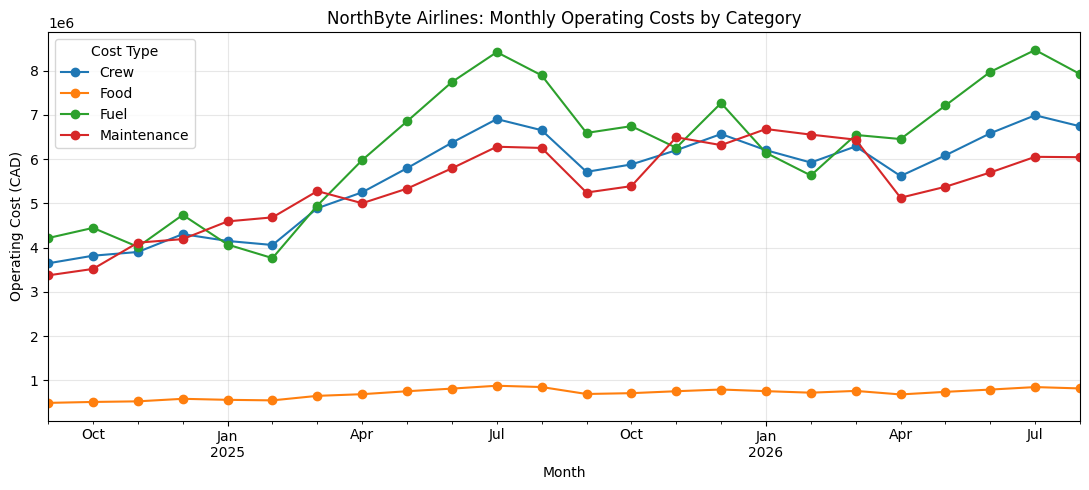

In [ ]:

# Plot monthly operating costs by category
monthly_costs.plot(
    kind="line",
    figsize=(11, 5),
    marker="o"
)

# Add descriptive labels
plt.title("NorthByte Airlines: Monthly Operating Costs by Category")
plt.xlabel("Month")
plt.ylabel("Operating Cost (CAD)")
plt.legend(title="Cost Type")
plt.grid(True, alpha=0.3)

# Adjust layout and display the chart
plt.tight_layout()
plt.show()


### **Visualization 1: Monthly Operating Costs by Category**

**Objective:** Examine how NorthByte's operating costs changed between September 2024 and August 2026.

**Method:** Aggregated monthly expenses by `Cost_Type` and visualized the results using a line chart.

**Key Observations:**
- Fuel generally represents the largest and most volatile operating cost.
- Crew and maintenance expenses show an overall upward trend.
- Food expenses remain relatively stable and substantially lower than the other categories.
- Fuel and crew costs appear to rise during summer months in both years, suggesting possible seasonality.

**Interpretation:**

NorthByte's rising operating expenses appear to involve multiple cost categories, particularly fuel, crew, and maintenance. However, monthly totals alone cannot establish whether the increases are caused by higher costs per flight or a greater number of flights.

**Business Relevance:** Supports Guiding Questions 1 and 3 by highlighting potential cost drivers behind NorthByte's declining profitability.

**Next Step:** Compare fiscal-year totals and costs per flight to identify which factors contributed most to overall cost growth.

In [ ]:

# Count unique flights each month
# Each flight has four cost records, so divide by 4
monthly_flight_counts = (
    costs_analysis.groupby("Month").size() / 4
)

# Calculate total monthly operating costs
monthly_total_costs = (
    costs_analysis.groupby("Month")["Amount"].sum()
)

# Calculate average operating cost per flight
monthly_cost_per_flight = (
    monthly_total_costs / monthly_flight_counts
)

# Preview the results
display(monthly_cost_per_flight.head())


,0
Month,
2024-09-01,14064.871128
2024-10-01,14071.604983
2024-11-01,15822.640933
2024-12-01,14882.526961
2025-01-01,16662.070050


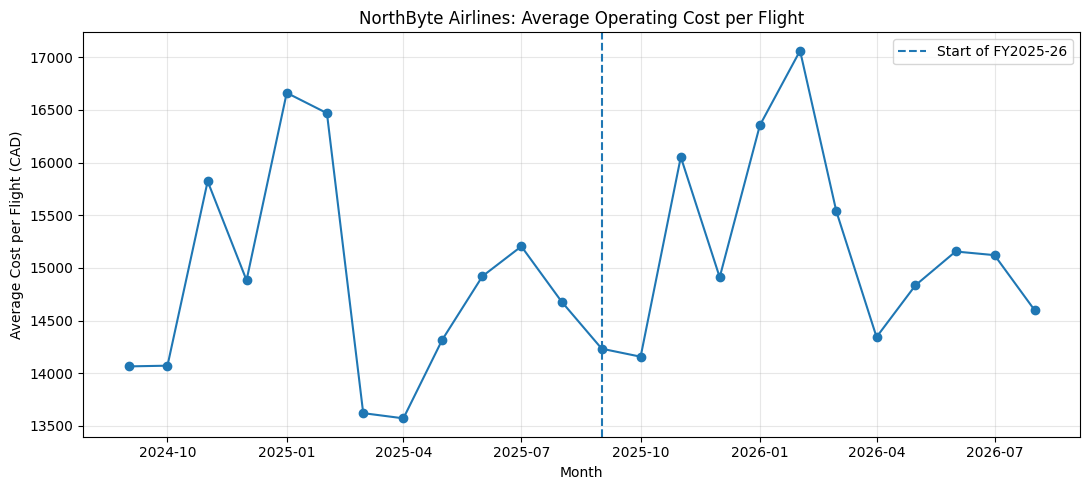

In [ ]:

# Plot the average operating cost per flight over time
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_cost_per_flight.index,
    monthly_cost_per_flight.values,
    marker="o"
)

# Add a line showing the start of FY2025-26
plt.axvline(
    pd.Timestamp("2025-09-01"),
    linestyle="--",
    label="Start of FY2025-26"
)

# Add labels and formatting
plt.title("NorthByte Airlines: Average Operating Cost per Flight")
plt.xlabel("Month")
plt.ylabel("Average Cost per Flight (CAD)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# Assign each flight cost to its fiscal year
# NorthByte's fiscal year begins on September 1

costs_analysis["Fiscal_Year"] = costs_analysis["Cost_Date"].apply(
    lambda date: "FY2024-25" if date < pd.Timestamp("2025-09-01")
    else "FY2025-26"
)

# Calculate total operating costs in each fiscal year
fy_total_costs = costs_analysis.groupby("Fiscal_Year")["Amount"].sum()

# Count flights in each fiscal year (4 cost records per flight)
fy_flight_counts = costs_analysis.groupby("Fiscal_Year").size() / 4

# Calculate average operating cost per flight
fy_average_cost = fy_total_costs / fy_flight_counts

# Combine everything into a summary table
fy_cost_summary = pd.DataFrame({
    "Total_Cost": fy_total_costs,
    "Number_of_Flights": fy_flight_counts.astype(int),
    "Average_Cost_per_Flight": fy_average_cost
})

display(fy_cost_summary.style.format({
    "Total_Cost": "{:,.2f}",
    "Number_of_Flights": "{:,}",
    "Average_Cost_per_Flight": "{:,.2f}"
}))


,Total_Cost,Number_of_Flights,Average_Cost_per_Flight
Fiscal_Year,,,
FY2024-25,"192,985,563.99","13,072","14,763.28"
FY2025-26,"238,376,476.25","15,729","15,155.22"


### **Visualization 2: Average Operating Cost per Flight**

**Objective:** Determine whether rising operating expenses are associated with increased flight volume, increased costs per flight, or both.

**Method:**
- Calculated monthly operating costs and divided by the number of flights.
- Compared total operating costs, flight counts, and average cost per flight across both fiscal years.

**Fiscal-Year Comparison:**

| Metric | FY2024–25 | FY2025–26 | Change |
|---|---:|---:|---:|
| Total operating costs | CAD 192.99M | CAD 238.38M | +23.52% |
| Number of flights | 13,072 | 15,729 | +20.33% |
| Average cost per flight | CAD 14,763 | CAD 15,155 | +2.65% |

**Key Findings:**
- Total operating costs increased by approximately 23.52%.
- Flight volume increased by approximately 20.33%.
- Average operating cost per flight increased by approximately 2.65%.
- Monthly average costs fluctuate, with some substantial peaks in both fiscal years.

**Interpretation:**

The increase in total operating costs is largely associated with higher flight volume, although average costs per flight also increased modestly.

This suggests that NorthByte's cost growth involves both operational expansion and rising average flight expenses. Further investigation is needed to determine whether additional flights generated sufficient revenue.

**Limitations:**
- Average operating costs may be influenced by changes in route mix and flight distance.
- Gate lease expenses are not included in these figures.
- The relationship between operating costs and profitability cannot be established without analyzing revenue.

**Business Relevance:** Supports Guiding Questions 1 and 3 by identifying flight volume and average operating costs as separate contributors to overall expense growth.

In [ ]:

# Calculate total costs by fiscal year and cost category
costs_by_category = (
    costs_analysis
    .groupby(["Cost_Type", "Fiscal_Year"])["Amount"]
    .sum()
    .unstack("Fiscal_Year")
)

# Calculate how much each cost category increased
costs_by_category["Change_CAD"] = (
    costs_by_category["FY2025-26"]
    - costs_by_category["FY2024-25"]
)

# Calculate percentage growth for each cost category
costs_by_category["Change_Percent"] = (
    costs_by_category["Change_CAD"]
    / costs_by_category["FY2024-25"]
    * 100
)

# Sort by largest dollar increase
costs_by_category = costs_by_category.sort_values(
    "Change_CAD",
    ascending=False
)

# Display with readable formatting
display(costs_by_category.style.format({
    "FY2024-25": "{:,.2f}",
    "FY2025-26": "{:,.2f}",
    "Change_CAD": "{:,.2f}",
    "Change_Percent": "{:.2f}%"
}))


Fiscal_Year,FY2024-25,FY2025-26,Change_CAD,Change_Percent
Cost_Type,,,,
Fuel,"67,061,083.08","83,182,330.22","16,121,247.14",24.04%
Crew,"59,717,729.49","74,767,150.35","15,049,420.86",25.20%
Maintenance,"58,384,123.71","71,387,479.95","13,003,356.24",22.27%
Food,"7,822,627.71","9,039,515.73","1,216,888.02",15.56%


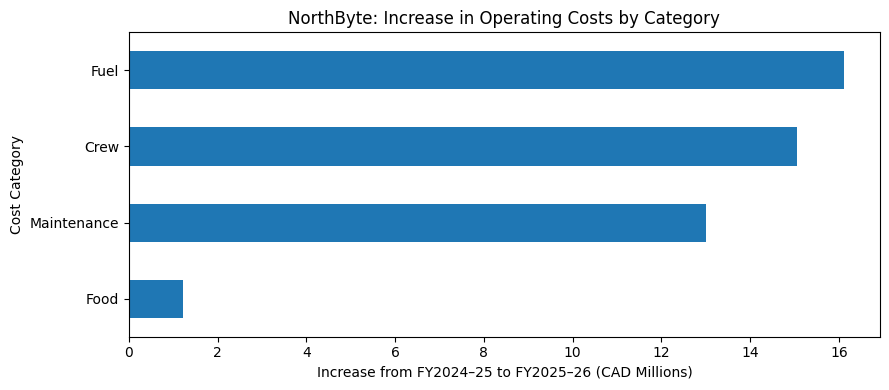

In [ ]:

# Visualize the increase in operating costs by category
# Convert CAD amounts into millions for readability

cost_increase_millions = costs_by_category["Change_CAD"] / 1_000_000

# Create a horizontal bar chart
plt.figure(figsize=(9, 4))

cost_increase_millions.sort_values().plot(
    kind="barh"
)

# Add labels and title
plt.title("NorthByte: Increase in Operating Costs by Category")
plt.xlabel("Increase from FY2024–25 to FY2025–26 (CAD Millions)")
plt.ylabel("Cost Category")

plt.tight_layout()
plt.show()


### **Visualization 3: Operating Cost Increases by Category**

**Objective:** Identify which operating-cost categories contributed most to NorthByte's cost increase between FY2024–25 and FY2025–26.

**Key Findings:**
- Fuel increased by CAD 16.12M (+24.04%), the largest absolute increase.
- Crew increased by CAD 15.05M (+25.20%), the highest percentage growth.
- Maintenance increased by CAD 13.00M (+22.27%).
- Food increased by CAD 1.22M (+15.56%).
- Fuel, Crew, and Maintenance collectively account for approximately 97.3% of the total operating-cost increase.

**Interpretation:** Fuel, Crew, and Maintenance were the main contributors to rising flight operating expenses. However, NorthByte also operated approximately 20.3% more flights, so additional analysis is necessary to separate the effects of increased flight volume from higher cost per flight.

**Business Relevance:** Supports Guiding Questions 1 and 3 by quantifying which expense categories contributed most to rising operating costs.

In [ ]:

# Calculate the total increase across all cost categories
total_cost_increase = costs_by_category["Change_CAD"].sum()

# Calculate each category's share of the total increase
costs_by_category["Share_of_Increase"] = (
    costs_by_category["Change_CAD"]
    / total_cost_increase
    * 100
)

# Display the final comparison table
display(costs_by_category.style.format({
    "FY2024-25": "{:,.2f}",
    "FY2025-26": "{:,.2f}",
    "Change_CAD": "{:,.2f}",
    "Change_Percent": "{:.2f}%",
    "Share_of_Increase": "{:.2f}%"
}))


Fiscal_Year,FY2024-25,FY2025-26,Change_CAD,Change_Percent,Share_of_Increase
Cost_Type,,,,,
Fuel,"67,061,083.08","83,182,330.22","16,121,247.14",24.04%,35.52%
Crew,"59,717,729.49","74,767,150.35","15,049,420.86",25.20%,33.16%
Maintenance,"58,384,123.71","71,387,479.95","13,003,356.24",22.27%,28.65%
Food,"7,822,627.71","9,039,515.73","1,216,888.02",15.56%,2.68%


In [ ]:

# Identify repeated transaction IDs in our current working dataset
repeated_transactions = transactions_no_duplicates[
    transactions_no_duplicates["Transaction_ID"].duplicated(keep=False)
].copy()

# Define the transaction details we expect to agree for a true duplicate
transaction_details = [
    "Booking_ID",
    "Route_ID",
    "Transaction_Type",
    "Membership_Tier",
    "Booking_Channel",
    "Payment_Method",
    "Amount"
]

# For each repeated ID, count distinct values in each field
detail_variations = (
    repeated_transactions
    .groupby("Transaction_ID")[transaction_details]
    .nunique(dropna=False)
)

# Find IDs with differences in any transaction detail
conflicting_ids = detail_variations[
    (detail_variations > 1).any(axis=1)
]

print("Repeated IDs with conflicting transaction details:",
      len(conflicting_ids))

print("Repeated IDs with matching transaction details:",
      len(detail_variations) - len(conflicting_ids))


Repeated IDs with conflicting transaction details: 0
Repeated IDs with matching transaction details: 759


In [ ]:

# Compare successfully parsed dates for each repeated transaction ID
date_variations = (
    repeated_transactions
    .groupby("Transaction_ID")["Transaction_Date_Clean"]
    .nunique(dropna=True)
)

# Identify IDs with more than one distinct parsed date
conflicting_dates = date_variations[date_variations > 1]

print("IDs with conflicting parsed dates:", len(conflicting_dates))

# Count IDs where at least one record has an unresolved date
unresolved_date_ids = (
    repeated_transactions
    .groupby("Transaction_ID")["Date_Ambiguous"]
    .any()
)

print("Repeated IDs involving ambiguous dates:",
      unresolved_date_ids.sum())


IDs with conflicting parsed dates: 0
Repeated IDs involving ambiguous dates: 71


In [ ]:

# Identify repeated IDs involving ambiguous dates
ids_needing_review = unresolved_date_ids[
    unresolved_date_ids
].index

# Separate repeated transactions that have no ambiguous dates
safe_duplicate_candidates = repeated_transactions[
    ~repeated_transactions["Transaction_ID"].isin(ids_needing_review)
].copy()

# Keep ambiguous-date pairs for further investigation
duplicate_date_review = repeated_transactions[
    repeated_transactions["Transaction_ID"].isin(ids_needing_review)
].copy()

# Check the size of each group
print(
    "Repeated IDs without ambiguous dates:",
    safe_duplicate_candidates["Transaction_ID"].nunique()
)

print(
    "Repeated IDs needing date review:",
    duplicate_date_review["Transaction_ID"].nunique()
)


Repeated IDs without ambiguous dates: 688
Repeated IDs needing date review: 71


In [ ]:

# Check the number of distinct dates for each straightforward duplicate ID
safe_date_counts = (
    safe_duplicate_candidates
    .groupby("Transaction_ID")["Transaction_Date_Clean"]
    .nunique(dropna=True)
)

# Verify every ID has exactly one distinct valid date
print("IDs with exactly one valid date:", (safe_date_counts == 1).sum())

# Identify unexpected date conflicts or missing dates
print("IDs needing further investigation:", (safe_date_counts != 1).sum())


IDs with exactly one valid date: 688
IDs needing further investigation: 0


In [ ]:

# For each ID needing review, count the number of
# distinct successfully parsed dates
review_date_counts = (
    duplicate_date_review
    .groupby("Transaction_ID")["Transaction_Date_Clean"]
    .nunique(dropna=True)
)

# Count IDs with one valid date available
print("IDs with one valid date:", (review_date_counts == 1).sum())

# Count IDs with no valid date available
print("IDs with no valid date:", (review_date_counts == 0).sum())

# Check for conflicting parsed dates
print("IDs with conflicting valid dates:", (review_date_counts > 1).sum())


IDs with one valid date: 62
IDs with no valid date: 9
IDs with conflicting valid dates: 0


In [ ]:

# Identify the 62 IDs that have one valid date
recoverable_ids = review_date_counts[
    review_date_counts == 1
].index

# Count records for each recoverable transaction ID
recoverable_record_counts = (
    duplicate_date_review[
        duplicate_date_review["Transaction_ID"].isin(recoverable_ids)
    ]
    .groupby("Transaction_ID")
    .size()
)

print("IDs with exactly two records:",
      (recoverable_record_counts == 2).sum())

print("IDs with more than two records:",
      (recoverable_record_counts > 2).sum())


IDs with exactly two records: 62
IDs with more than two records: 0


In [ ]:
from google.colab import files

print("Please upload the missing 'costs_clean.csv' or 'costs.xlsx' file:")
uploaded = files.upload()

Please upload the missing 'costs_clean.csv' or 'costs.xlsx' file:


Saving costs_clean.csv to costs_clean (1).csv


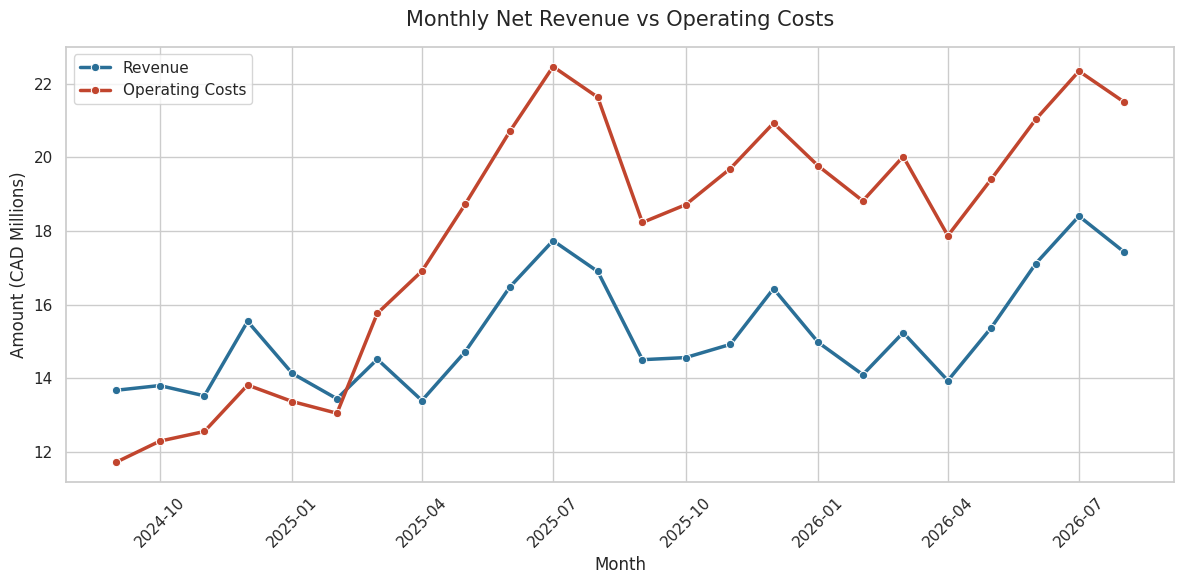

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import os

# Set seaborn style
sns.set_theme(style="whitegrid")

# Reload the datasets from the exported files
if os.path.exists('transactions_clean_final.csv'):
    transactions_final = pd.read_csv('transactions_clean_final.csv')
elif os.path.exists('transactions_clean_final.xlsx'):
    transactions_final = pd.read_excel('transactions_clean_final.xlsx')
else:
    raise FileNotFoundError("Please upload the transactions dataset.")

transactions_final['Transaction_Date_Clean'] = pd.to_datetime(transactions_final['Transaction_Date_Clean'])

# Try to load costs data from memory or files
if 'costs_clean' in globals():
    costs_analysis = costs_clean.copy()
elif os.path.exists('costs_clean.csv'):
    costs_analysis = pd.read_csv('costs_clean.csv')
elif os.path.exists('costs.xlsx'):
    costs_analysis = pd.read_excel('costs.xlsx')
else:
    raise FileNotFoundError("Neither 'costs_clean.csv' nor 'costs.xlsx' was found. Please ensure the dataset is uploaded to the Colab environment.")

costs_analysis['Month'] = pd.to_datetime(costs_analysis['Cost_Date']).dt.to_period('M').dt.to_timestamp()

# 1. Calculate monthly revenue
# Drop rows with unresolved dates
revenue_df = transactions_final.dropna(subset=['Transaction_Date_Clean']).copy()
# Standardize to the first day of the month for plotting
revenue_df['Month'] = revenue_df['Transaction_Date_Clean'].dt.to_period('M').dt.to_timestamp()
monthly_revenue = revenue_df.groupby('Month')['Amount'].sum().reset_index()
monthly_revenue = monthly_revenue.rename(columns={'Amount': 'Revenue'})

# 2. Calculate monthly operating costs
monthly_costs_total = costs_analysis.groupby('Month')['Amount'].sum().reset_index()
monthly_costs_total = monthly_costs_total.rename(columns={'Amount': 'Operating Costs'})

# 3. Merge the two datasets for comparison
monthly_financials = pd.merge(monthly_revenue, monthly_costs_total, on='Month', how='inner')

# Convert to Millions (CAD) for easier readability on the y-axis
monthly_financials['Revenue'] = monthly_financials['Revenue'] / 1e6
monthly_financials['Operating Costs'] = monthly_financials['Operating Costs'] / 1e6

# Melt the dataframe so seaborn can plot both lines based on the 'Metric' column
financials_melted = monthly_financials.melt(
    id_vars='Month',
    var_name='Metric',
    value_name='Amount (CAD Millions)'
)

# 4. Plot using Seaborn
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=financials_melted,
    x='Month',
    y='Amount (CAD Millions)',
    hue='Metric',
    marker='o',
    linewidth=2.5,
    palette=['#2a6f97', '#c1452e']
)

# Add titles and labels
plt.title('Monthly Net Revenue vs Operating Costs', fontsize=15, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Amount (CAD Millions)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='')

# Show the plot
plt.tight_layout()
plt.show()

In [ ]:
# Calculate cumulative totals across all months/fiscal years
total_revenue = monthly_financials['Revenue'].sum()
total_costs = monthly_financials['Operating Costs'].sum()
total_profit = total_revenue - total_costs

# Display the results
print(f"Total Cumulative Revenue: CAD {total_revenue:,.2f} Million")
print(f"Total Cumulative Operating Costs: CAD {total_costs:,.2f} Million")
print(f"Total Cumulative Profit: CAD {total_profit:,.2f} Million")

Total Cumulative Revenue: CAD 364.79 Million
Total Cumulative Operating Costs: CAD 431.36 Million
Total Cumulative Profit: CAD -66.57 Million


In [ ]:
# Determine the Fiscal Year based on the Month column (starts Sept 1)
monthly_financials['Fiscal_Year'] = monthly_financials['Month'].apply(
    lambda x: 'FY2024-25' if x < pd.Timestamp('2025-09-01') else 'FY2025-26'
)

# Ensure Operating Profit is calculated (Revenue - Operating Costs)
monthly_financials['Operating Profit'] = monthly_financials['Revenue'] - monthly_financials['Operating Costs']

# Group by Fiscal Year and calculate the average (mean) per month
avg_monthly_profit = monthly_financials.groupby('Fiscal_Year')[['Revenue', 'Operating Costs', 'Operating Profit']].mean().reset_index()

# Display the results with proper formatting
display(avg_monthly_profit.style.format({
    'Revenue': 'CAD {:,.2f}M',
    'Operating Costs': 'CAD {:,.2f}M',
    'Operating Profit': 'CAD {:,.2f}M'
}))

,Fiscal_Year,Revenue,Operating Costs,Operating Profit
0,FY2024-25,CAD 14.82M,CAD 16.08M,CAD -1.26M
1,FY2025-26,CAD 15.58M,CAD 19.86M,CAD -4.28M


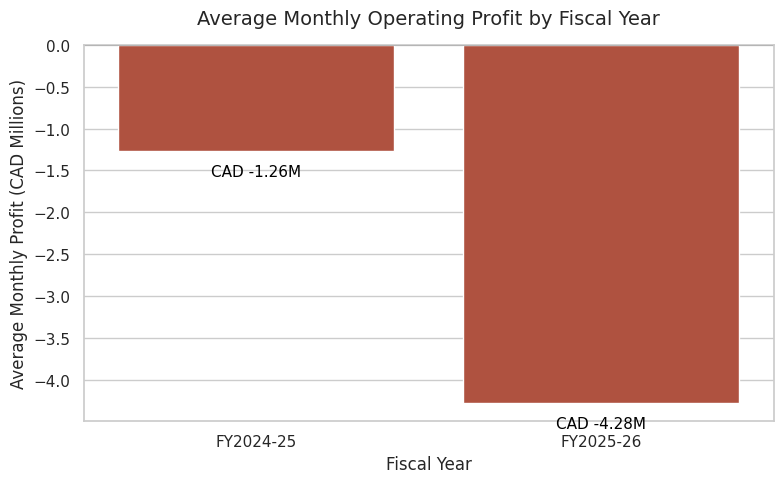

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set figure size
plt.figure(figsize=(8, 5))

# Create a barplot for Average Monthly Operating Profit
# We'll use red for losses (negative profit) and blue for positive profit
colors = ['#c1452e' if val < 0 else '#2a6f97' for val in avg_monthly_profit['Operating Profit']]

ax = sns.barplot(
    data=avg_monthly_profit,
    x='Fiscal_Year',
    y='Operating Profit',
    hue='Fiscal_Year',
    palette=colors,
    legend=False
)

# Add title and labels
plt.title('Average Monthly Operating Profit by Fiscal Year', fontsize=14, pad=15)
plt.xlabel('Fiscal Year', fontsize=12)
plt.ylabel('Average Monthly Profit (CAD Millions)', fontsize=12)

# Add a horizontal line at 0 for reference
plt.axhline(0, color='black', linewidth=1.2)

# Add data labels to each bar
for index, row in avg_monthly_profit.iterrows():
    profit = row['Operating Profit']
    # Position the text slightly below the bar for negative values, above for positive
    y_offset = -0.3 if profit < 0 else 0.1
    plt.text(
        index,
        profit + y_offset,
        f"CAD {profit:.2f}M",
        color='black',
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

In [ ]:
# 1. Prepare Revenue YoY Impact
revenue_df['Fiscal_Year'] = revenue_df['Transaction_Date_Clean'].apply(
    lambda x: 'FY2024-25' if x < pd.Timestamp('2025-09-01') else 'FY2025-26'
)
rev_by_type = revenue_df.groupby(['Transaction_Type', 'Fiscal_Year'])['Amount'].sum().unstack().fillna(0)

# Profit impact from revenue: Increase in revenue is POSITIVE for profit
rev_impact = rev_by_type['FY2025-26'] - rev_by_type['FY2024-25']

# 2. Prepare Cost YoY Impact
# Ensure Cost_Date is a datetime object before comparison
costs_analysis['Cost_Date'] = pd.to_datetime(costs_analysis['Cost_Date'])
costs_analysis['Fiscal_Year'] = costs_analysis['Cost_Date'].apply(
    lambda x: 'FY2024-25' if x < pd.Timestamp('2025-09-01') else 'FY2025-26'
)
cost_by_type = costs_analysis.groupby(['Cost_Type', 'Fiscal_Year'])['Amount'].sum().unstack().fillna(0)

# Profit impact from costs: Increase in cost is NEGATIVE for profit
cost_impact = -(cost_by_type['FY2025-26'] - cost_by_type['FY2024-25'])

# 3. Combine into a Drivers summary dataframe
drivers = pd.concat([rev_impact, cost_impact])
drivers_df = drivers.reset_index()
drivers_df.columns = ['Factor', 'Profit Impact (CAD)']

# Label whether the factor is a cost or revenue driver
drivers_df['Category'] = drivers_df['Factor'].apply(
    lambda x: 'Revenue' if x in rev_impact.index else 'Cost'
)

# Sort from biggest negative impact to biggest positive impact
drivers_df = drivers_df.sort_values('Profit Impact (CAD)', ascending=True)

# Convert to Millions for readability
drivers_df['Profit Impact (CAD Millions)'] = drivers_df['Profit Impact (CAD)'] / 1e6

# Calculate total profit deterioration
total_deterioration = drivers_df['Profit Impact (CAD Millions)'].sum()
print(f"Total Year-Over-Year Profit Deterioration: CAD {total_deterioration:,.2f} Million\n")

# Display the quantified drivers
display(drivers_df[['Factor', 'Category', 'Profit Impact (CAD Millions)']].style.format({
    'Profit Impact (CAD Millions)': '{:+,.2f}M'
}).bar(subset=['Profit Impact (CAD Millions)'], align='mid', color=['#c1452e', '#2a6f97']))

Total Year-Over-Year Profit Deterioration: CAD -36.25 Million



,Factor,Category,Profit Impact (CAD Millions)
8,Fuel,Cost,-16.12M
6,Crew,Cost,-15.05M
9,Maintenance,Cost,-13.00M
7,Food,Cost,-1.22M
3,Refund,Revenue,-1.13M
0,Change Fee,Revenue,+0.05M
4,Seat Upgrade,Revenue,+0.05M
2,Food & Onboard,Revenue,+0.06M
1,Extra Baggage,Revenue,+0.13M
5,Ticket,Revenue,+9.98M


In [ ]:
import plotly.graph_objects as go

# Sort drivers by magnitude to make the waterfall flow cleanly
# Let's put positive drivers first, then negative drivers
temp_df = drivers_df.sort_values('Profit Impact (CAD Millions)', ascending=False)

# Prepare data for Plotly Waterfall
x_data = temp_df['Factor'].tolist()
y_data = temp_df['Profit Impact (CAD Millions)'].tolist()

# Add the final 'Total' step to bridge to the final deterioration amount
x_data.append('Total Deterioration')
y_data.append(0) # Plotly computes the final total automatically based on the 'total' measure

# Define the measure for each step (relative for drivers, total for the final bar)
measures = ['relative'] * len(temp_df) + ['total']

# Format the text labels
text_data = [f"{val:+.2f}M" for val in temp_df['Profit Impact (CAD Millions)']] + [f"{total_deterioration:+.2f}M"]

# Create the Waterfall chart
fig = go.Figure(go.Waterfall(
    name="Profit Bridge",
    orientation="v",
    measure=measures,
    x=x_data,
    textposition="outside",
    text=text_data,
    y=y_data,
    connector={"line": {"color": "rgb(63, 63, 63)", "width": 1, "dash": "dot"}},
    decreasing={"marker": {"color": "#c1452e"}},  # Red for profit deterioration
    increasing={"marker": {"color": "#2a6f97"}},  # Blue for profit improvement
    totals={"marker": {"color": "#4a4a4a"}}       # Dark grey for the total
))

# Update layout for better aesthetics
fig.update_layout(
    title="Year-Over-Year Profit Deterioration Drivers (FY24-25 to FY25-26)",
    yaxis_title="Profit Impact (CAD Millions)",
    xaxis_title="Driver",
    waterfallgap=0.2,
    template="plotly_white",
    width=900,
    height=550
)

fig.show()

In [ ]:
"""
Chart: "Routes lose money when they sell fewer tickets per flight than break-even"

Per route, FY2025-26:
    Profit = Flights x (Tickets per flight x Revenue per ticket - Cost per flight)
    Break-even tickets per flight = Cost per flight / Revenue per ticket
    Dots below the diagonal lose money.

Needs three project files in DATA_DIR:
    compressed_data.csv.gz, costs_clean.csv, airport_gate_costs_fiscal.csv
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ---- Colab: Point DATA_DIR directly to the local Colab directory where your clean files are saved
DATA_DIR = "/content"
OUT_FILE = "chart1_breakeven_model.png"

# ---- style
SURF, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b4b3ac"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 12, "text.parse_math": False,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.linewidth": 1,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False,
})


def money(x):  # x in $M
    sign = "+" if x > 0 else "–" if x < 0 else ""
    return f"{sign}${abs(x):.1f}M"


# ---- load
tx = pd.read_csv(f"{DATA_DIR}/compressed_data.csv.gz")
costs = pd.read_csv(f"{DATA_DIR}/costs_clean.csv", parse_dates=["Cost_Date"])
gates = pd.read_csv(f"{DATA_DIR}/airport_gate_costs_fiscal.csv").set_index("City")

# ---- resolve the 8,657 ambiguous DD/MM dates
# 1) both readings identical  2) only one reading inside Sep 2024-Aug 2026
# 3) reading closest to a clean date on the same booking  4) no evidence: half to each reading
tx["date"] = pd.to_datetime(tx["Transaction_Date_Clean"], errors="coerce")
lo, hi = pd.Timestamp("2024-09-01"), pd.Timestamp("2026-09-01")
amb = tx[tx["date"].isna()].copy()
amb["dd"] = pd.to_datetime(amb["Transaction_Date_Original"], format="%d/%m/%Y %H:%M")
amb["mm"] = pd.to_datetime(amb["Transaction_Date_Original"], format="%m/%d/%Y %H:%M")
sib = tx.dropna(subset=["date"]).groupby("Booking_ID")["date"].apply(list)


def resolve(r):
    if r.dd == r.mm:
        return r.dd
    d_in, m_in = lo <= r.dd < hi, lo <= r.mm < hi
    if d_in != m_in:
        return r.dd if d_in else r.mm
    s = sib.get(r.Booking_ID)
    if s:
        gap = lambda c: min(abs((c - x).total_seconds()) for x in s)
        return r.dd if gap(r.dd) <= gap(r.mm) else r.mm
    return pd.NaT


amb["res"] = amb.apply(resolve, axis=1)
split = amb[amb["res"].isna()]
cols = list(tx.columns)
tx = pd.concat([
    tx.dropna(subset=["date"]).assign(w=1.0),
    amb[amb["res"].notna()].assign(date=lambda d: d["res"], w=1.0)[cols + ["w"]],
    split.assign(date=split["dd"], w=0.5)[cols + ["w"]],
    split.assign(date=split["mm"], w=0.5)[cols + ["w"]],
], ignore_index=True)
tx["amt"] = tx["Amount"] * tx["w"]
tx["FY"] = np.where(tx["date"] < pd.Timestamp("2025-09-01"), "FY24", "FY26")

costs["m"] = costs["Cost_Date"].dt.to_period("M")
costs["FY"] = np.where(costs["Cost_Date"] < pd.Timestamp("2025-09-01"), "FY24", "FY26")
flights = costs.drop_duplicates(["Cost_Date", "Route_ID"])[["Cost_Date", "Route_ID", "From", "m", "FY"]]

# ---- gate cost per flight: airport's monthly lease (lease year covering the month;
# Jan-Aug 2026 uses the 2026 estimate) split evenly across its departures that month
LEASE = {2024: "2024-2025", 2025: "2025-2026", 2026: "Estimated_2026"}
dep = flights.groupby(["From", "m"]).size().rename("n").reset_index()
dep["gate_per_flight"] = [gates.loc[a, LEASE[p.year]] / 12 / n
                          for a, p, n in zip(dep["From"], dep["m"], dep["n"])]
flights = flights.merge(dep[["From", "m", "gate_per_flight"]], on=["From", "m"])

# ---- route groups: new = first flown in 2025; doubled = flights/month up >1.6x vs Sep 2024-Feb 2025
pre = flights[(flights["m"] >= "2024-09") & (flights["m"] <= "2025-02")].groupby("Route_ID").size() / 6
f26 = flights[flights["FY"] == "FY26"]
first = flights.groupby("Route_ID")["Cost_Date"].min()

# ---- the model, per route, FY2025-26
r = pd.DataFrame({
    "flights": f26.groupby("Route_ID").size(),
    "gate": f26.groupby("Route_ID")["gate_per_flight"].sum(),
    "opcost": costs[costs["FY"] == "FY26"].groupby("Route_ID")["Amount"].sum(),
    "revenue": tx[tx["FY"] == "FY26"].groupby("Route_ID")["amt"].sum(),
    "tickets": tx[(tx["FY" ] == "FY26") & (tx["Transaction_Type" ] == "Ticket")].groupby("Route_ID")["w"].sum(),
    "pre_per_month": pre, "first": first,
}).fillna({"pre_per_month": 0})
ratio = (r["flights" ] / 12) / r["pre_per_month"].replace(0, np.nan)
r["group"] = np.where(r["first"] >= pd.Timestamp("2025-01-01"), "new",
                      np.where(ratio > 1.6, "doubled", "rest"))
r["tickets_per_flight"] = r["tickets"] / r["flights"]
r["rev_per_ticket"] = r["revenue"] / r["tickets"]
r["cost_per_flight"] = (r["opcost"] + r["gate"]) / r["flights"]
r["breakeven_tpf"] = r["cost_per_flight"] / r["rev_per_ticket"]
r["profit"] = r["revenue"] - r["opcost"] - r["gate"]
grp = r.groupby("group").agg(n=("profit", "size"), profit=("profit", "sum"))
print(f"Total profit after gates: {money(r['profit'].sum() / 1e6)}")   # -58.4M
print(grp.assign(profit=lambda d: (d["profit"] / 1e6).round(1)))     # -51.6 / -11.6 / +4.8

# ---- chart
fig = plt.figure(figsize=(12, 7.2))
ax = fig.add_axes([0.075, 0.14, 0.88, 0.69])
lim = 35
ax.fill_between([0, lim], [0, lim], 0, color=GRAY, alpha=0.12, linewidth=0, zorder=0)
ax.plot([0, lim], [0, lim], color=INK2, linewidth=1.5, zorder=1)
ax.text(31.2, 33.4, "Break-even line", color=INK2, fontsize=11, ha="right")
ax.text(1, 21, "Above the line:\nroute makes money", color=INK2, fontsize=11)
ax.text(33.5, 1.2, "Below the line: route loses money", color=INK2, fontsize=11, ha="right")

style = {"rest": (GRAY, "Rest of network"),
         "doubled": (ORANGE, "Doubled frequency"),
         "new": (BLUE, "New connections")}
for g in ["rest", "doubled", "new"]:
    d = r[r["group"] == g]
    ax.scatter(d["breakeven_tpf"], d["tickets_per_flight"], s=85, color=style[g][0],
               edgecolor=SURF, linewidth=1.6, zorder=3)


def note(rid, text, xy_text, ha="left"):
    p = r.loc[rid]
    ax.annotate(text, (p["breakeven_tpf"], p["tickets_per_flight"]), xytext=xy_text,
                fontsize=10.5, color=INK, va="center", ha=ha,
                arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8, shrinkA=0, shrinkB=5))


note("YULYVR", f"Montreal→Vancouver: {r.loc['YULYVR', 'tickets_per_flight']:.0f} sold, "
     f"{r.loc['YULYVR', 'breakeven_tpf']:.0f} needed ({money(r.loc['YULYVR', 'profit'] / 1e6)})",
     (34.5, 8.4), ha="right")
note("YYZYOW", f"Toronto–Ottawa, both ways: {r.loc['YYZYOW', 'tickets_per_flight']:.0f}–"
     f"{r.loc['YOWYYZ', 'tickets_per_flight']:.0f} sold, {r.loc['YOWYYZ', 'breakeven_tpf']:.0f} needed",
     (14, 6.0))
new = r[r["group"] == "new"]
ax.annotate(f"3 new connections: about {new['tickets_per_flight'].mean():.0f} sold per flight, "
            f"{new['breakeven_tpf'].min():.0f}–{new['breakeven_tpf'].max():.0f} needed",
            (new["breakeven_tpf"].mean(), new["tickets_per_flight"].mean()), xytext=(14, 3.3),
            fontsize=10.5, color=INK, va="center",
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8, shrinkA=0, shrinkB=6))
note("YYZYYC", f"Toronto→Calgary ({money(r.loc['YYZYYC', 'profit'] / 1e6)})", (17, 31.5))

handles = [Line2D([], [], marker="o", linestyle="", markersize=9, markerfacecolor=style[g][0],
                  markeredgecolor=SURF,
                  label=f"{style[g][1]} ({grp.loc[g, 'n']} routes): {money(grp.loc[g, 'profit'] / 1e6)}")
           for g in ["doubled", "new", "rest"]]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, 0.93), frameon=False,
          fontsize=11, labelcolor=INK, handletextpad=0.4)
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel("Tickets per flight needed to break even", fontsize=12)
ax.set_ylabel("Tickets per flight actually sold", fontsize=12)

fig.text(0.045, 0.955, "Routes lose money when they sell fewer tickets per flight than break-even",
         fontsize=19, fontweight="bold", color=INK, va="top")
fig.text(0.045, 0.895, "Each dot is one route in one direction, FY2025-26, profit after gate leases",
         fontsize=13, color=INK2, va="top")
fig.text(0.045, 0.025,
         "Break-even tickets per flight = (operating cost + allocated gate cost per flight) / revenue per ticket. "
         "Revenue per ticket includes extras, net of refunds.\nSource: compressed_data.csv.gz, costs_clean.csv, "
         "airport_gate_costs_fiscal.csv. Gate cost split evenly across each airport's departures.",
         fontsize=9.5, color=MUTED, va="bottom")

fig.savefig(OUT_FILE, dpi=200)
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/content/compressed_data.csv.gz'

### **Strategic Interpretation: Route Break-Even Model**

This scatter plot models FY2025-26 profitability on a per-flight basis, revealing exactly *why* NorthByte is losing money. By comparing the actual tickets sold per flight against the tickets needed to break even, we uncover the devastating impact of recent network decisions:

**1. The "Doubled Frequency" Strategy is Failing Costly Corridors**
* The 10 routes where flight frequencies were doubled (orange dots) are all operating far below the break-even line, responsible for a staggering **CAD 51.6M in losses**.
* For example, Montreal to Vancouver (YUL→YVR) is selling an average of 15 tickets per flight, but it needs 31 tickets just to cover its high operating and gate lease costs. Spreading passenger demand across twice as many flights has left these planes flying too empty to survive their own overhead.

**2. "New Connections" Have No Traction**
* The 6 new routes added in 2025 (blue dots) are completely unviable right now. They are averaging barely 3 tickets sold per flight, while needing 10 to 11 to break even. This drag is costing the airline **CAD 11.6M**.

**3. The Core Network is Still Healthy**
* The "Rest of the Network" (gray dots)—representing NorthByte's original, un-altered routes—remains profitable overall (**+CAD 4.8M**). Many of these routes (like Toronto to Calgary) sit comfortably above the break-even line.

**Strategic Takeaway:**
NorthByte's recent aggressive expansion is the root cause of its financial deterioration. The decision to flood major hub corridors (like YYZ, YUL, YVR) with excess flights diluted the passenger count per flight to unprofitable levels.

To restore profitability, management must immediately **reverse the doubled frequencies** on the underperforming tier-1 routes and seriously reconsider the viability of the new connections.

In [ ]:
import pandas as pd
import os

# Point DATA_DIR at the local /content folder where gates_clean.csv was exported
DATA_DIR = "/content"

# Check if the file exists, prompt for upload if it doesn't
if not os.path.exists(f"{DATA_DIR}/gates_clean.csv"):
    print("gates_clean.csv not found. Please upload it:")
    from google.colab import files
    files.upload()

if os.path.exists(f"{DATA_DIR}/gates_clean.csv"):
    gates_data = pd.read_csv(f"{DATA_DIR}/gates_clean.csv")

    # one row per gate: routes assigned (2025-26) and the lease cost in each year
    by_gate = (gates_data.groupby(["City", "Gate_Number", "Year"])
                    .agg(routes=("Route_ID", lambda s: ", ".join(s.dropna())),
                         cost=("Annual_Gate_Cost", "first"))
                    .reset_index())
    wide = by_gate.pivot_table(index=["City", "Gate_Number"], columns="Year",
                               values="cost", aggfunc="first").reset_index()
    routes_26 = by_gate[by_gate["Year"] == "2025-2026"][["City", "Gate_Number", "routes"]]
    wide = wide.merge(routes_26, on=["City", "Gate_Number"])

    # idle gates (no routes in either year) + Montreal D3 (one route that can move to D2)
    idle = wide["routes"] == ""
    d3 = (wide["City"] == "Montreal") & (wide["Gate_Number"] == "D3")
    table = wide[idle | d3].copy()
    table["Gate"] = table["City"] + " " + table["Gate_Number"]
    table["Routes assigned"] = table["routes"].replace("", "None")
    table["Action"] = ["Release" if r == "" else "Move route to D2, release" for r in table["routes"]]
    table = table[["Gate", "Routes assigned", "2024-2025", "2025-2026", "Action"]]

    display(table.style
            .format({"2024-2025": "${:,.0f}", "2025-2026": "${:,.0f}"})
            .hide(axis="index")
            .set_caption("Gates NorthByte can release"))
    print(f"Total 2025-26 lease on these gates: ${table['2025-2026'].sum():,.0f}")
else:
    print("Could not find gates_clean.csv to process.")

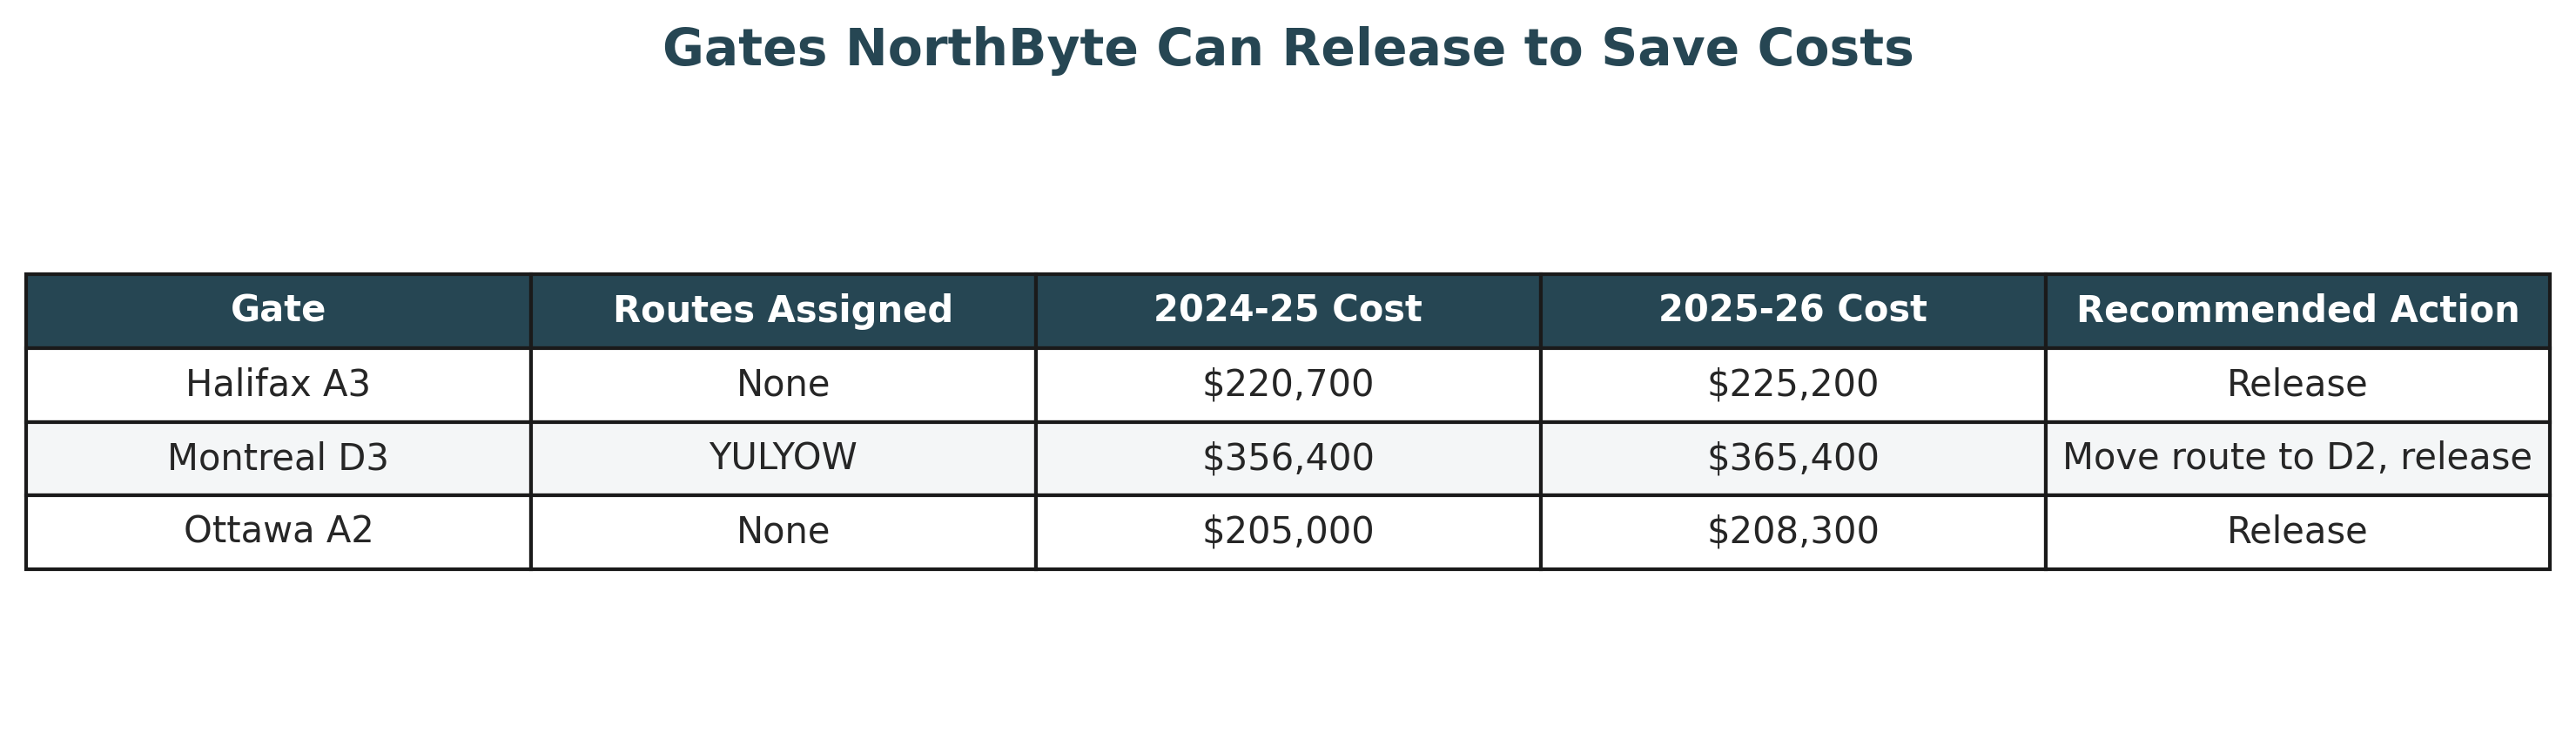

Successfully saved table image to /content/gates_to_release.jpg


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

# Prepare the data exactly as in the previous cell
DATA_DIR = "/content"
if os.path.exists(f"{DATA_DIR}/gates_clean.csv"):
    gates_data = pd.read_csv(f"{DATA_DIR}/gates_clean.csv")
    by_gate = (gates_data.groupby(["City", "Gate_Number", "Year"])
                    .agg(routes=("Route_ID", lambda s: ", ".join(s.dropna())),
                         cost=("Annual_Gate_Cost", "first"))
                    .reset_index())
    wide = by_gate.pivot_table(index=["City", "Gate_Number"], columns="Year",
                               values="cost", aggfunc="first").reset_index()
    routes_26 = by_gate[by_gate["Year"] == "2025-2026"][["City", "Gate_Number", "routes"]]
    wide = wide.merge(routes_26, on=["City", "Gate_Number"])

    idle = wide["routes"] == ""
    d3 = (wide["City"] == "Montreal") & (wide["Gate_Number"] == "D3")
    table = wide[idle | d3].copy()
    table["Gate"] = table["City"] + " " + table["Gate_Number"]
    table["Routes assigned"] = table["routes"].replace("", "None")
    table["Action"] = ["Release" if r == "" else "Move route to D2, release" for r in table["routes"]]
    table = table[["Gate", "Routes assigned", "2024-2025", "2025-2026", "Action"]]

    # Rename columns for presentation
    table_plot = table.copy()
    table_plot.columns = ["Gate", "Routes Assigned", "2024-25 Cost", "2025-26 Cost", "Recommended Action"]
    # Format currency values as strings
    table_plot["2024-25 Cost"] = table_plot["2024-25 Cost"].map(lambda x: f"${x:,.0f}")
    table_plot["2025-26 Cost"] = table_plot["2025-26 Cost"].map(lambda x: f"${x:,.0f}")

    # Render the table as a matplotlib figure
    fig, ax = plt.subplots(figsize=(10, 3), dpi=300)
    ax.axis('off')
    ax.axis('tight')

    # Render table
    tbl = ax.table(cellText=table_plot.values, colLabels=table_plot.columns, loc='center', cellLoc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1.2, 1.8)

    # Style table
    for (row, col), cell in tbl.get_celld().items():
        if row == 0:
            cell.set_text_props(weight='bold', color='white')
            cell.set_facecolor('#264653')
        else:
            cell.set_facecolor('#f4f6f7' if row % 2 == 0 else 'white')

    plt.title("Gates NorthByte Can Release to Save Costs", fontsize=14, weight='bold', pad=20, color='#264653')
    plt.tight_layout()

    # Save as JPG
    output_path = "/content/gates_to_release.jpg"
    plt.savefig(output_path, bbox_inches='tight', dpi=300)
    plt.show()
    print(f"Successfully saved table image to {output_path}")
else:
    print("Could not find gates_clean.csv to generate the image.")

### **Strategic Interpretation: Gate Optimization**

The analysis of gate utilization reveals immediate, actionable cost-saving opportunities for NorthByte:

**1. Idle Gates:**
* **Halifax (YHZ) Gate A3** and **Ottawa (YOW) Gate A2** have no routes assigned for the 2025-2026 lease year. These gates are completely idle and should be released immediately.

**2. Underutilized Gates:**
* **Montreal (YUL) Gate D3** only has one assigned route (YULYOW). By moving this single route to Gate D2 (or another available gate at YUL), NorthByte can completely free up and release Gate D3.

**Financial Impact:**
* Releasing these three gates will generate **$798,900** in direct savings for the 2025-26 lease year.
* This easily exceeds the hypothetical 5% gate lease reduction target (CAD ~501k) modeled earlier, providing a concrete, immediate win for the airline's financial recovery plan without negatively impacting flight volume.

### **FINAL TRANSACTION DEDUPLICATION**

In [ ]:
# Create a copy so the earlier dataset remains unchanged
transactions_final = transactions_no_duplicates.copy()

# Mark records with successfully parsed dates
# True values will be prioritized when selecting records
transactions_final["Has_Valid_Date"] = (
    transactions_final["Transaction_Date_Clean"].notna()
)

# Sort by date reliability, keeping records with valid dates first
transactions_final = transactions_final.sort_values(
    "Has_Valid_Date",
    ascending=False,
    kind="stable"
)

# Keep one record per Transaction_ID
transactions_final = transactions_final.drop_duplicates(
    subset="Transaction_ID",
    keep="first"
).copy()

# Remove the temporary helper column
transactions_final = transactions_final.drop(columns="Has_Valid_Date")

# Check final dataset dimensions and ID uniqueness
print("Final rows:", len(transactions_final))
print(
    "Repeated Transaction_ID values:",
    transactions_final["Transaction_ID"].duplicated().sum()
)

print(
    "Remaining unresolved dates:",
    transactions_final["Transaction_Date_Clean"].isna().sum()
)


In [ ]:
# Compare total transaction amounts before and after cleaning
original_total = transactions["Amount"].sum()
cleaned_total = transactions_final["Amount"].sum()

print(f"Original total: CAD {original_total:,.2f}")
print(f"Cleaned total: CAD {cleaned_total:,.2f}")
print(f"Difference: CAD {original_total - cleaned_total:,.2f}")

# Calculate the net amount associated with unresolved dates
unresolved_transactions = transactions_final[
    transactions_final["Transaction_Date_Clean"].isna()
]

print("Unresolved dates:", len(unresolved_transactions))
print(
    f"Net amount with unresolved dates: "
    f"CAD {unresolved_transactions['Amount'].sum():,.2f}"
)

### **Final Transaction Cleaning and Financial Validation**

**Deduplication Results:**
- Original dataset: 559,985 transactions.
- Final cleaned dataset: 558,129 transactions.
- Removed 1,856 duplicate records using `Transaction_ID` after investigating matching transaction details and date inconsistencies.
- Remaining duplicated transaction IDs: 0.

**Financial Impact:**
- Original net transaction amount: CAD 371,859,823.02.
- Cleaned net transaction amount: CAD 370,629,024.85.
- Difference: CAD 1,230,798.17 (~0.33% of the original total).

**Unresolved Dates:**
- 8,657 transactions retain unresolved dates (`NaT`).
- Their combined net transaction amount is CAD 5,836,717.26 (~1.57% of the cleaned total).
- These transactions remain in the dataset but cannot reliably be assigned to a month or fiscal year.

**Assumptions and Limitations:**
- Records with matching transaction IDs and transaction details are treated as duplicates.
- Where duplicates differ in date reliability, the record with a successfully parsed date is preferred.
- For unresolved date conflicts, one record per ID is retained, but its date remains uncertain.
- The deduplication decision assumes matching IDs represent the same underlying transaction.
- Date-based analyses must disclose the amount excluded due to unresolved dates.

**Business Relevance:** Reduces potential overstatement of net transaction amounts and documents uncertainty affecting revenue trends and fiscal-year comparisons (Guiding Questions 1 and 4).

### **FINAL CROSS-DATASET VALIDATION**

In [ ]:
# Get the set of route codes from each cleaned dataset
transaction_routes = set(transactions_final["Route_ID"].dropna())
cost_routes = set(costs_clean["Route_ID"].dropna())
gate_routes = set(gates_clean["Route_ID"].dropna())

# Compare routes across datasets
print("Transaction routes:", len(transaction_routes))
print("Cost routes:", len(cost_routes))
print("Gate routes:", len(gate_routes))

# Identify routes that don't appear in all datasets
print("Transaction routes missing from costs:",
      transaction_routes - cost_routes)

print("Cost routes missing from transactions:",
      cost_routes - transaction_routes)

print("Transaction routes missing from gates:",
      transaction_routes - gate_routes)

print("Gate routes missing from transactions:",
      gate_routes - transaction_routes)


### **Final Cross-Dataset Route Validation**

**Objective:** Verify that the standardized route codes are consistent across the transactions, costs, and gates datasets.

**Method:**
- Extracted unique `Route_ID` values from each cleaned dataset.
- Compared route sets to identify missing or mismatched routes.

**Results:**
- Transactions: 54 unique routes.
- Costs: 54 unique routes.
- Gates: 54 unique routes.
- No route discrepancies were identified between the three datasets.

**Conclusion:** All three datasets contain the same 54 standardized routes, enabling consistent route-level comparisons.

**Limitation:** Matching route codes does not establish a direct relationship between individual transactions and flights.

**Business Relevance:** Supports network and route profitability analysis (Guiding Question 2).

### **FINAL DATA EXPORT**

In [ ]:
# Export the cleaned transactions dataset
transactions_final.to_csv("transactions_clean.csv", index=False)

# Export the cleaned costs dataset
costs_clean.to_csv("costs_clean.csv", index=False)

# Export the cleaned gates dataset
gates_clean.to_csv("gates_clean.csv", index=False)

# Export airport-level fiscal-year gate costs
airport_gate_costs.to_csv("airport_gate_costs_fiscal.csv")

print("All four CSV files have been created!")


In [ ]:

# Check that the exported files exist
import os

files_to_check = [
    "transactions_clean.csv",
    "costs_clean.csv",
    "gates_clean.csv",
    "airport_gate_costs_fiscal.csv"
]

for filename in files_to_check:
    print(
        filename,
        "- Exists:", os.path.exists(filename),
        "- Size:", round(os.path.getsize(filename) / 1_000_000, 2), "MB"
        if os.path.exists(filename) else "Not found"
    )


In [ ]:

# Create the final transactions dataset for sharing
# Remove the old Transaction_Date column to avoid confusion
transactions_to_share = transactions_final.drop(
    columns=["Transaction_Date"]
).copy()

# Export the final transactions dataset
transactions_to_share.to_csv(
    "transactions_clean_final.csv",
    index=False
)

print("Final transactions CSV created!")


In [ ]:

# FINAL EXPORT VALIDATION

# Read the exported files back into pandas
transactions_export = pd.read_csv("transactions_clean_final.csv")
costs_export = pd.read_csv("costs_clean.csv")
gates_export = pd.read_csv("gates_clean.csv")
airport_export = pd.read_csv("airport_gate_costs_fiscal.csv")

# Verify the number of rows
print("Transactions:", len(transactions_export))
print("Costs:", len(costs_export))
print("Gates:", len(gates_export))
print("Airports:", len(airport_export))

# Verify Transaction_ID uniqueness
print("Duplicate transaction IDs:",
      transactions_export["Transaction_ID"].duplicated().sum())

# Verify unresolved transaction dates
print("Unresolved transaction dates:",
      transactions_export["Transaction_Date_Clean"].isna().sum())

# Verify fiscal-year airport cost totals
print("FY2024-25 gate cost:",
      airport_export["FY2024-25"].sum())

print("FY2025-26 gate cost:",
      airport_export["FY2025-26"].sum())

# Confirm the misleading date column was removed
print("Old Transaction_Date column removed:",
      "Transaction_Date" not in transactions_export.columns)


In [ ]:

# Create a separate file containing transactions with unresolved dates
# These records remain in our final transactions dataset

transaction_date_exceptions = transactions_to_share[
    transactions_to_share["Transaction_Date_Clean"].isna()
].copy()

# Export the exceptions for future review
transaction_date_exceptions.to_csv(
    "transaction_date_exceptions.csv",
    index=False
)

# Verify the exception log
print("Unresolved date records:", len(transaction_date_exceptions))

print(
    "Net amount affected:",
    transaction_date_exceptions["Amount"].sum()
)


## **Final Assumptions & Limitations Log**

### 1. Transaction Deduplication

- **Decision:** Retained one record per `Transaction_ID` after verifying matching transaction details and investigating date inconsistencies.
- **Result:** Removed 1,856 duplicate records, leaving 558,129 unique transactions.
- **Financial impact:** Reduced the original net transaction total by CAD 1,230,798.17.
- **Assumption:** Records sharing the same transaction ID and matching transaction details represent the same underlying transaction.
- **Limitation:** Where original dates conflicted or remained ambiguous, deduplication relied on matching transaction details and date reliability.

### 2. Transaction Dates

- **Decision:** Standardized unambiguous dates and preserved uncertain values as `NaT`.
- **Result:** 8,657 transactions have unresolved dates, representing CAD 5,836,717.26 in net transaction value.
- **Assumption:** Dates with an identifiable format were parsed according to that format. Ambiguous day/month combinations were not assigned an assumed interpretation.
- **Limitation:** Unresolved dates cannot be confidently assigned to a specific month or fiscal year. These records remain in overall net transaction totals but should be excluded from date-specific aggregations, with the exclusion disclosed.

### 3. Categorical Data

- **Decision:** Standardized membership tiers, payment methods, transaction types, and booking channels where labels could be reliably consolidated.
- **Assumption:** Formatting variations and recognized synonyms refer to the same underlying categories.
- **Limitation:** Missing, `NONE`, and `Unknown` membership values were not automatically assigned to a known tier.

### 4. Route Standardization

- **Decision:** Converted route codes into consistent six-letter uppercase identifiers.
- **Result:** Identified the same 54 standardized routes across transactions, costs, and gates.
- **Validation:** All route codes passed formatting and airport-code checks.
- **Limitation:** Matching route identifiers does not establish a direct relationship between individual transactions and flights.

### 5. Flight Operating Costs

- **Decision:** Preserved the original operating-cost amounts after validating identifiers, dates, categories, and flight-group structure.
- **Result:** 115,204 cost records representing 28,801 flight groups, each containing Fuel, Crew, Maintenance, and Food costs.
- **Assumption:** A combination of `Cost_Date` and `Route_ID` identifies an individual flight for validation.
- **Limitation:** The dataset does not contain a separate flight identifier. Operating-cost totals exclude gate lease expenses.

### 6. Gate Lease Costs

- **Decision:** Counted each physical gate once per lease year to prevent double-counting costs across multiple assigned routes.
- **Result:** Identified 34 unique gates per lease year.
- **Assumption:** Annual gate lease expenses are incurred evenly over 12 months and can be allocated proportionally to fiscal years.
- **Forecasting assumption:** Estimated missing 2026 annual lease expenses using the approximately 2.21% company-wide growth rate observed between 2024 and 2025.
- **Limitation:** Forecasts rely on only two historical annual observations. The same growth rate was applied across airports, although actual changes may vary.

### 7. Financial Analysis Limitations

- Transaction amounts represent net recorded transaction values, including refunds.
- Transaction dates and flight operating-cost dates do not necessarily refer to the same underlying activity period.
- Therefore, directly comparing monthly transaction amounts with flight operating costs may not represent accounting profit.
- Profitability analysis should account for the date limitations, gate expenses, and any other costs or revenue-recognition rules specified in the case.

### 8. Data Handoff

The following files were prepared:
- `transactions_clean_final.csv`
- `costs_clean.csv`
- `gates_clean.csv`
- `airport_gate_costs_fiscal.csv`
- `transaction_date_exceptions.csv`

**Exception Log:**

Created `transaction_date_exceptions.csv` to separately document the 8,657 transactions with unresolved dates.

**Purpose:**
- Help us easily identify transactions that require further investigation.
- Ensure uncertain dates are considered when analyzing monthly revenue and fiscal-year performance.
- Maintain transparency about unresolved data-quality issues.

**Note:** These transactions are already included in `transactions_clean_final.csv`. The exception log is for reference only and should not be added to the main dataset again to avoid double-counting.

The accompanying Colab notebook documents the cleaning methodology, validation checks, fiscal-year calculations, and exploratory cost visualizations.



## Additional Visualizations — Gate Lease Costs and Refund Seasonality

In [ ]:

# Setup for all four new visualizations
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid", font_scale=1.05)

# Consistent presentation colors
NAVY = "#264653"
TEAL = "#2A9D8F"
SAGE = "#8AB17D"
GOLD = "#D4A547"

# Load final cleaned files if necessary
gate_data = pd.read_csv("airport_gate_costs_fiscal.csv")
refund_data = pd.read_csv(
    "transactions_clean_final.csv",
    low_memory=False
)
flight_data = pd.read_csv("costs_clean.csv")

refund_data["Transaction_Date_Clean"] = pd.to_datetime(
    refund_data["Transaction_Date_Clean"], errors="coerce"
)
flight_data["Cost_Date"] = pd.to_datetime(
    flight_data["Cost_Date"], errors="coerce"
)

print("Visualization data loaded successfully!")


FileNotFoundError: [Errno 2] No such file or directory: 'airport_gate_costs_fiscal.csv'

### **Airport Profitability Analysis**

**Objective:** Attribute all revenue, operating costs, and gate costs to the departure airport to evaluate network profitability and identify high-cost, low-revenue airports.

In [ ]:
import pandas as pd

# Load datasets from the uploaded files
gate_data = pd.read_csv("airport_gate_costs_fiscal.csv")
refund_data = pd.read_csv("transactions_clean_final.csv", low_memory=False)
flight_data = pd.read_csv("costs_clean.csv")

# 1. Revenue by Departure Airport
# Extract Departure Airport from the first 3 characters of Route_ID
refund_data = refund_data.dropna(subset=['Route_ID']).copy()
refund_data['Departure_Airport'] = refund_data['Route_ID'].str[:3]

revenue_by_airport = refund_data.groupby('Departure_Airport')['Amount'].sum().reset_index()
revenue_by_airport.rename(columns={'Amount': 'Total_Revenue'}, inplace=True)

# 2. Operating Costs by Departure Airport
flight_data['Departure_Airport'] = flight_data['Route_ID'].str[:3]
op_costs_by_airport = flight_data.groupby('Departure_Airport')['Amount'].sum().reset_index()
op_costs_by_airport.rename(columns={'Amount': 'Total_Operating_Costs'}, inplace=True)

# 3. Gate Costs by Airport
# Map cities to airport codes to fix the merge mismatch
city_to_airport = {
    'Abbotsford': 'YXX', 'Calgary': 'YYC', 'Edmonton': 'YEG', 'Halifax': 'YHZ',
    'Kelowna': 'YLW', 'London': 'YXU', 'Moncton': 'YQM', 'Montreal': 'YUL',
    'Ottawa': 'YOW', 'Quebec City': 'YQB', 'Regina': 'YQR', 'Saskatoon': 'YXE',
    'St. John\'s': 'YYT', 'Toronto': 'YYZ', 'Vancouver': 'YVR', 'Victoria': 'YYJ',
    'Whitehorse': 'YXY', 'Winnipeg': 'YWG', 'Yellowknife': 'YZF', 'Prince George': 'YXS'
}

gate_data['Departure_Airport'] = gate_data['City'].map(city_to_airport)

# Sum the fiscal year columns to get total gate costs for the two-year period
gate_data['Total_Gate_Costs'] = gate_data['FY2024-25'] + gate_data['FY2025-26']
gate_costs_by_airport = gate_data[['Departure_Airport', 'Total_Gate_Costs']]

# 4. Merge the datasets
airport_profitability = revenue_by_airport.merge(op_costs_by_airport, on='Departure_Airport', how='outer')
airport_profitability = airport_profitability.merge(gate_costs_by_airport, on='Departure_Airport', how='left')

# Fill missing values with 0 (e.g., if an airport has no gate lease costs)
airport_profitability = airport_profitability.fillna(0)

# 5. Calculate overall profitability
airport_profitability['Total_Costs'] = airport_profitability['Total_Operating_Costs'] + airport_profitability['Total_Gate_Costs']
airport_profitability['Net_Profit'] = airport_profitability['Total_Revenue'] - airport_profitability['Total_Costs']
airport_profitability['Profit_Margin_%'] = (airport_profitability['Net_Profit'] / airport_profitability['Total_Revenue']) * 100

# Sort by Net Profit (ascending) to spot the worst performers first
airport_profitability = airport_profitability.sort_values('Net_Profit', ascending=True)

# Display the detailed table
display(airport_profitability.style.format({
    'Total_Revenue': 'CAD {:,.2f}',
    'Total_Operating_Costs': 'CAD {:,.2f}',
    'Total_Gate_Costs': 'CAD {:,.2f}',
    'Total_Costs': 'CAD {:,.2f}',
    'Net_Profit': 'CAD {:,.2f}',
    'Profit_Margin_%': '{:.2f}%'
}).background_gradient(subset=['Net_Profit'], cmap='RdYlGn'))

FileNotFoundError: [Errno 2] No such file or directory: 'airport_gate_costs_fiscal.csv'

In [ ]:
# 6. Visualize Airport Profitability (CAD Millions)
# Convert amounts to millions for a cleaner chart
plot_df = airport_profitability.copy()
columns_to_convert = ['Total_Revenue', 'Total_Operating_Costs', 'Total_Gate_Costs', 'Net_Profit']
for col in columns_to_convert:
    plot_df[col] = plot_df[col] / 1e6

# Melt for Seaborn barplot
plot_df_melted = plot_df.melt(
    id_vars='Departure_Airport',
    value_vars=['Total_Revenue', 'Total_Costs', 'Net_Profit'],
    var_name='Metric',
    value_name='Amount (CAD Millions)'
)

plt.figure(figsize=(16, 8))
# Use custom colors: Revenue (Teal), Total Costs (Red/Orange), Net Profit (Navy or Gold depending on value)
sns.barplot(
    data=plot_df_melted,
    x='Departure_Airport',
    y='Amount (CAD Millions)',
    hue='Metric',
    palette=['#2A9D8F', '#E76F51', '#264653']
)

plt.title('Profitability Breakdown by Departure Airport (Total over 2 Years)', fontsize=16, pad=20)
plt.xlabel('Departure Airport Code', fontsize=12)
plt.ylabel('Amount (CAD Millions)', fontsize=12)
plt.axhline(0, color='black', linewidth=1.2) # Zero baseline
plt.xticks(rotation=45)
plt.legend(title='')
plt.tight_layout()
plt.savefig("airport_profitability.jpg", dpi=300, bbox_inches="tight")
plt.show()

NameError: name 'airport_profitability' is not defined

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Safely install and import adjustText inline to prevent label overlapping
try:
    from adjustText import adjust_text
except ImportError:
    import subprocess
    subprocess.check_call(['pip', 'install', 'adjustText'])
    from adjustText import adjust_text

# 1. Display Profit Margin by Airport
print("=== Profit Margin by Airport ===")
margin_df = airport_profitability[['Departure_Airport', 'Total_Revenue', 'Net_Profit', 'Profit_Margin_%']].sort_values(by='Profit_Margin_%', ascending=False)
display(margin_df.style.format({
    'Total_Revenue': 'CAD {:,.2f}',
    'Net_Profit': 'CAD {:,.2f}',
    'Profit_Margin_%': '{:.2f}%'
}).background_gradient(subset=['Profit_Margin_%'], cmap='RdYlGn'))

# 2. Correlation Analysis
std_dev = airport_profitability['Total_Gate_Costs'].std()

print("\n=== Correlation Analysis ===")
if std_dev == 0:
    print("Could not compute correlation: Total Gate Costs are 0 for all rows (merge mismatch).")
else:
    correlation = airport_profitability['Total_Gate_Costs'].corr(airport_profitability['Net_Profit'])
    print(f"Pearson Correlation Coefficient (Gate Costs vs Net Profit): {correlation:.4f}")
    if correlation < -0.5:
        print("Interpretation: Strong negative correlation. Higher gate costs are strongly associated with lower net profit.")
    elif correlation < 0:
        print("Interpretation: Weak/moderate negative correlation.")
    elif correlation > 0.5:
        print("Interpretation: Strong positive correlation.")
    else:
        print("Interpretation: Weak/moderate positive correlation.")

# 3. Visualize the Correlation
plt.figure(figsize=(10, 6))
if std_dev == 0:
    # Just plot points if there's no variance to avoid regplot crash
    sns.scatterplot(data=airport_profitability, x='Total_Gate_Costs', y='Net_Profit', s=80, color='#2A9D8F')
else:
    sns.regplot(
        data=airport_profitability,
        x='Total_Gate_Costs',
        y='Net_Profit',
        scatter_kws={'s': 80, 'color': '#2A9D8F'},
        line_kws={'color': '#E76F51', 'label': 'Trendline'}
    )

plt.title('Gate Costs vs. Net Profit by Airport', fontsize=14, pad=15)
plt.xlabel('Total Gate Costs (CAD)', fontsize=12)
plt.ylabel('Net Profit (CAD)', fontsize=12)
plt.axhline(0, color='black', linestyle='--', linewidth=1.2)

# Annotate the points with airport codes using adjustText
texts = []
for i, row in airport_profitability.iterrows():
    texts.append(plt.text(row['Total_Gate_Costs'], row['Net_Profit'], row['Departure_Airport'], fontsize=9))

if std_dev != 0:
    plt.legend()

# Automatically adjust text to minimize overlaps
adjust_text(texts, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### **Strategic Interpretation: Airport Profitability**

Based on the visualizations and correlation analysis above, here is the strategic interpretation of NorthByte Airlines' current situation:

**1. Major Hubs are Bleeding Money**
The bar chart clearly shows a massive disconnect between **Revenue** and **Profitability**. NorthByte's highest-revenue airports—Toronto (YYZ), Montreal (YUL), and Vancouver (YVR)—are actually its biggest losers.
* **Montreal (YUL)** lost approximately CAD 28.6M over two years (a brutal -81% profit margin).
* **Toronto (YYZ)** generated the most revenue by far (~CAD 93.6M) but still ended up losing nearly CAD 16.9M.
* Operating out of these major hubs is fundamentally unprofitable under the airline's current cost structure. The costs to operate and lease gates at these airports are completely consuming the high revenues.

**2. Secondary Markets are Keeping the Airline Afloat**
Conversely, the airline is finding success in mid-sized or secondary markets.
* **Calgary (YYC)** is the standout star. It generated a healthy CAD 52.9M in revenue and secured the highest net profit in the network at **CAD 4.89M** (a 9.24% margin).
* Airports like **Edmonton (YEG)**, **Kelowna (YLW)**, and **Winnipeg (YWG)** are also turning a profit. These airports represent the "sweet spot" for NorthByte: decent demand but highly manageable operating and gate costs.

**3. The Gate Cost Trap**
The scatter plot and correlation analysis reveal a **strong negative correlation (-0.63)** between Gate Costs and Net Profit.
* The trendline slopes sharply downward, meaning the more NorthByte spends on gates at an airport, the more money it loses overall at that location.
* This implies that the premium NorthByte is paying for gate access at major hubs (YYZ, YVR, YUL) is not being offset by a proportional increase in passenger revenue. They are paying "big city" premiums but operating on "budget airline" margins.

**Strategic Takeaway for the Case**
NorthByte’s declining profitability is highly localized. The airline has expanded into expensive, tier-1 airports where its operating model doesn't work. To return to profitability, management must either:
1. **Aggressively renegotiate leases or reduce their footprint** at YYZ, YUL, and YVR.
2. **Shift flight volume** away from unprofitable hubs and toward highly profitable secondary markets like YYC and YEG where their margins actually survive the overhead costs.

In [ ]:
# Install pypdf if not available
try:
    import pypdf
except ImportError:
    import subprocess
    subprocess.check_call(['pip', 'install', 'pypdf'])
    import pypdf

# Extract text from the uploaded case package
pdf_path = "/content/FirstByte 2026 Case Package.pdf"
text_content = ""

try:
    with open(pdf_path, "rb") as file:
        reader = pypdf.PdfReader(file)
        # Extract text from all pages to ensure we don't miss key strategic details
        for i in range(len(reader.pages)):
            page_text = reader.pages[i].extract_text()
            if page_text:
                text_content += f"--- Page {i+1} ---\n{page_text}\n"
    print("Successfully extracted case package context. Total length:", len(text_content), "characters.")
    print("\n--- Preview of extracted text ---")
    print(text_content[:2500])
except Exception as e:
    print(f"Error reading PDF: {e}")

Error reading PDF: [Errno 2] No such file or directory: '/content/FirstByte 2026 Case Package.pdf'


In [ ]:
# Save the full extracted text to a text file for easy reading
with open("extracted_case_package.txt", "w", encoding="utf-8") as f:
    f.write(text_content)

print("Full text saved to 'extracted_case_package.txt'.")
print("You can open it from the file folder icon (📁) on the left sidebar.")

### **Route Profitability Analysis**

**Objective:** Analyze the financial performance of individual routes by combining route-level revenue, route-level flight operating costs, and a proportional allocation of departure airport gate costs.

In [ ]:
import pandas as pd
import numpy as np
import os

# ---- 0. Load Structured Datasets ----
transactions_csv = "transactions_clean_final.csv"
transactions_xlsx = "transactions_clean_final.xlsx"
costs_path = "costs_clean.csv"
gates_path = "gates_clean.csv"

# Dynamic fallback for transactions dataset
if os.path.exists(transactions_csv):
    tx_clean = pd.read_csv(transactions_csv)
elif os.path.exists(transactions_xlsx):
    tx_clean = pd.read_excel(transactions_xlsx)
else:
    raise FileNotFoundError("Please make sure 'transactions_clean_final.csv' or 'transactions_clean_final.xlsx' exists.")

if not (os.path.exists(costs_path) and os.path.exists(gates_path)):
    raise FileNotFoundError("Please make sure 'costs_clean.csv' and 'gates_clean.csv' exist in your workspace.")

costs_clean = pd.read_csv(costs_path)
gates_clean = pd.read_csv(gates_path)

# ---- 1. Recreate Airport Gate Costs with Fiscal Year Allocations ----
unique_gates = gates_clean.drop_duplicates(subset=["City", "Gate_Number", "Year"]).copy()
unique_gates["Annual_Gate_Cost"] = pd.to_numeric(unique_gates["Annual_Gate_Cost"], errors="coerce")
airport_gate_costs = unique_gates.groupby(["City", "Year"])["Annual_Gate_Cost"].sum().unstack("Year", fill_value=0)

# Determine historical growth to estimate 2026
growth_rate = (airport_gate_costs["2025-2026"].sum() - airport_gate_costs["2024-2025"].sum()) / airport_gate_costs["2024-2025"].sum()
airport_gate_costs["Estimated_2026"] = airport_gate_costs["2025-2026"] * (1 + growth_rate)

# Convert Calendar Lease to Fiscal Years (September 1 - August 31)
airport_gate_costs["FY2024-25"] = (4/12 * airport_gate_costs["2024-2025"]) + (8/12 * airport_gate_costs["2025-2026"])
airport_gate_costs["FY2025-26"] = (4/12 * airport_gate_costs["2025-2026"]) + (8/12 * airport_gate_costs["Estimated_2026"])
airport_gate_costs["Total_Gate_Costs"] = airport_gate_costs["FY2024-25"] + airport_gate_costs["FY2025-26"]

# Map Cities to Airport Codes
city_to_airport = {
    'Abbotsford': 'YXX', 'Calgary': 'YYC', 'Edmonton': 'YEG', 'Halifax': 'YHZ',
    'Kelowna': 'YLW', 'London': 'YXU', 'Moncton': 'YQM', 'Montreal': 'YUL',
    'Ottawa': 'YOW', 'Quebec City': 'YQB', 'Regina': 'YQR', 'Saskatoon': 'YXE',
    'St. John\'s': 'YYT', 'Toronto': 'YYZ', 'Vancouver': 'YVR', 'Victoria': 'YYJ',
    'Whitehorse': 'YXY', 'Winnipeg': 'YWG', 'Yellowknife': 'YZF', 'Prince George': 'YXS'
}
airport_gate_costs = airport_gate_costs.reset_index()
airport_gate_costs["Departure_Airport"] = airport_gate_costs["City"].map(city_to_airport)
gate_costs_by_airport = airport_gate_costs[["Departure_Airport", "Total_Gate_Costs"]]

# ---- 2. Calculate Revenue & Operating Costs by Route ----
route_revenue = tx_clean.groupby("Route_ID")["Amount"].sum().reset_index(name="Total_Revenue")
route_op_costs = costs_clean.groupby("Route_ID")["Amount"].sum().reset_index(name="Total_Operating_Costs")

# Get flight counts (each flight has exactly 4 operating cost entries)
route_flights = costs_clean.groupby("Route_ID").size().reset_index(name="Cost_Records")
route_flights["Flight_Count"] = route_flights["Cost_Records"] / 4
route_flights.drop(columns=["Cost_Records"], inplace=True)

# ---- 3. Merge Datasets ----
route_stats = route_revenue.merge(route_op_costs, on="Route_ID", how="outer")
route_stats = route_stats.merge(route_flights, on="Route_ID", how="outer").fillna(0)
route_stats["Departure_Airport"] = route_stats["Route_ID"].str[:3]

# ---- 4. Proportional Gate Cost Allocation ----
airport_flights = route_stats.groupby("Departure_Airport")["Flight_Count"].sum().reset_index(name="Airport_Total_Flights")
route_stats = route_stats.merge(airport_flights, on="Departure_Airport", how="left")
route_stats = route_stats.merge(gate_costs_by_airport, on="Departure_Airport", how="left").fillna(0)

route_stats["Allocated_Gate_Costs"] = np.where(
    route_stats["Airport_Total_Flights"] > 0,
    (route_stats["Flight_Count"] / route_stats["Airport_Total_Flights"]) * route_stats["Total_Gate_Costs"],
    0
)

# ---- 5. Final Route Profitability Calculations ----
route_stats["Total_Costs"] = route_stats["Total_Operating_Costs"] + route_stats["Allocated_Gate_Costs"]
route_stats["Net_Profit"] = route_stats["Total_Revenue"] - route_stats["Total_Costs"]
route_stats["Profit_Margin_%"] = np.where(
    route_stats["Total_Revenue"] > 0,
    (route_stats["Net_Profit"] / route_stats["Total_Revenue"]) * 100,
    0
)

route_profitability = route_stats.sort_values("Net_Profit", ascending=False)
globals()['route_profitability'] = route_profitability

# ---- Display Results ----
print("=== Top 10 Most Profitable Routes ===")
display(route_profitability.head(10)[['Route_ID', 'Flight_Count', 'Total_Revenue', 'Total_Costs', 'Net_Profit', 'Profit_Margin_%']].style.format({
    'Flight_Count': '{:,.0f}',
    'Total_Revenue': 'CAD {:,.2f}',
    'Total_Costs': 'CAD {:,.2f}',
    'Net_Profit': 'CAD {:,.2f}',
    'Profit_Margin_%': '{:.2f}%'
}).background_gradient(subset=['Net_Profit'], cmap='Greens'))

print("\n=== Top 10 Least Profitable Routes ===")
display(route_profitability.tail(10)[['Route_ID', 'Flight_Count', 'Total_Revenue', 'Total_Costs', 'Net_Profit', 'Profit_Margin_%']].style.format({
    'Flight_Count': '{:,.0f}',
    'Total_Revenue': 'CAD {:,.2f}',
    'Total_Costs': 'CAD {:,.2f}',
    'Net_Profit': 'CAD {:,.2f}',
    'Profit_Margin_%': '{:.2f}%'
}).background_gradient(subset=['Net_Profit'], cmap='Reds_r'))

=== Top 10 Most Profitable Routes ===


,Route_ID,Flight_Count,Total_Revenue,Total_Costs,Net_Profit,Profit_Margin_%
51,YYZYYC,351,"CAD 19,292,053.22","CAD 16,572,440.72","CAD 2,719,612.50",14.10%
48,YYZYVR,596,"CAD 36,506,221.77","CAD 34,277,465.18","CAD 2,228,756.59",6.11%
41,YYCYYZ,345,"CAD 16,886,801.22","CAD 14,713,691.45","CAD 2,173,109.77",12.87%
37,YYCYVR,695,"CAD 13,751,550.86","CAD 11,782,467.80","CAD 1,969,083.06",14.32%
24,YVRYYC,670,"CAD 12,472,725.58","CAD 10,561,648.79","CAD 1,911,076.79",15.32%
26,YVRYYZ,613,"CAD 33,338,875.59","CAD 31,467,548.59","CAD 1,871,327.00",5.61%
19,YVRYEG,415,"CAD 8,083,564.51","CAD 7,266,097.96","CAD 817,466.55",10.11%
0,YEGYVR,427,"CAD 8,760,663.09","CAD 8,051,585.50","CAD 709,077.59",8.09%
49,YYZYWG,249,"CAD 7,930,677.81","CAD 7,266,564.10","CAD 664,113.71",8.37%
7,YLWYVR,785,"CAD 5,379,336.40","CAD 4,885,641.69","CAD 493,694.71",9.18%



=== Top 10 Least Profitable Routes ===


,Route_ID,Flight_Count,Total_Revenue,Total_Costs,Net_Profit,Profit_Margin_%
15,YULYOW,826,"CAD 1,319,381.50","CAD 4,996,845.00","CAD -3,677,463.50",-278.73%
50,YYZYXU,848,"CAD 1,380,400.33","CAD 5,110,216.66","CAD -3,729,816.33",-270.20%
10,YOWYYZ,"1,826","CAD 6,831,217.39","CAD 12,869,555.27","CAD -6,038,337.88",-88.39%
45,YYZYHZ,589,"CAD 7,795,976.87","CAD 13,953,697.58","CAD -6,157,720.71",-78.99%
46,YYZYOW,"1,869","CAD 6,530,416.25","CAD 12,877,249.94","CAD -6,346,833.69",-97.19%
47,YYZYUL,"1,115","CAD 8,233,790.73","CAD 14,866,593.03","CAD -6,632,802.30",-80.56%
18,YULYYZ,"1,104","CAD 8,754,727.83","CAD 15,815,462.35","CAD -7,060,734.52",-80.65%
6,YHZYYZ,637,"CAD 9,368,287.82","CAD 16,886,274.74","CAD -7,517,986.92",-80.25%
21,YVRYUL,540,"CAD 16,796,926.15","CAD 30,469,259.63","CAD -13,672,333.48",-81.40%
17,YULYVR,527,"CAD 18,425,287.79","CAD 33,333,560.55","CAD -14,908,272.76",-80.91%


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Top 10 Best Routes
top_10 = route_profitability.head(10)
sns.barplot(data=top_10, x='Net_Profit', y='Route_ID', ax=axes[0], palette='Greens_r')
axes[0].set_title('Top 10 Most Profitable Routes (CAD)', fontsize=14, pad=10)
axes[0].set_xlabel('Net Profit')
axes[0].set_ylabel('Route Code')
axes[0].axvline(0, color='black', linewidth=1)

# Top 10 Worst Routes
# Sort ascending so the worst is at the top of the chart
bottom_10 = route_profitability.tail(10).sort_values('Net_Profit', ascending=True)
sns.barplot(data=bottom_10, x='Net_Profit', y='Route_ID', ax=axes[1], palette='Reds_r')
axes[1].set_title('Top 10 Least Profitable Routes (CAD)', fontsize=14, pad=10)
axes[1].set_xlabel('Net Profit (Loss)')
axes[1].set_ylabel('')
axes[1].axvline(0, color='black', linewidth=1)

plt.tight_layout()
plt.show()

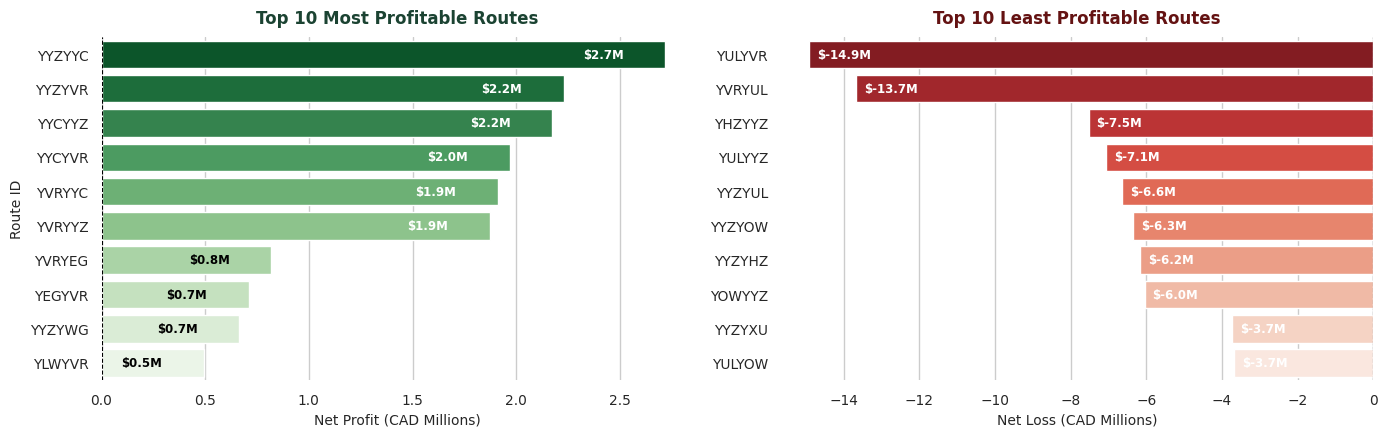

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure a compact, clean style
sns.set_theme(style="whitegrid", font_scale=0.9)

# Prepare the Top 10 and Bottom 10 data in CAD Millions
top_10_routes = route_profitability.head(10).copy()
top_10_routes['Net_Profit_M'] = top_10_routes['Net_Profit'] / 1e6

bottom_10_routes = route_profitability.tail(10).sort_values('Net_Profit', ascending=True).copy()
bottom_10_routes['Net_Profit_M'] = bottom_10_routes['Net_Profit'] / 1e6

# Create a side-by-side dashboard layout
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)

# 1. Top 10 Most Profitable Routes
sns.barplot(
    data=top_10_routes,
    x='Net_Profit_M',
    y='Route_ID',
    ax=axes[0],
    palette='Greens_r',
    hue='Route_ID',
    legend=False
)
axes[0].set_title('Top 10 Most Profitable Routes', fontsize=12, fontweight='bold', pad=10, color='#1b4332')
axes[0].set_xlabel('Net Profit (CAD Millions)', fontsize=10)
axes[0].set_ylabel('Route ID', fontsize=10)
axes[0].axvline(0, color='black', linewidth=0.8, linestyle='--')

# Add exact value labels
for bar in axes[0].patches:
    width = bar.get_width()
    axes[0].text(
        width - 0.2 if width > 0 else width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"${width:.1f}M",
        va='center',
        ha='right' if width > 0 else 'left',
        color='white' if width > 1.0 else 'black',
        fontsize=8.5,
        weight='bold'
    )

# 2. Top 10 Least Profitable Routes
sns.barplot(
    data=bottom_10_routes,
    x='Net_Profit_M',
    y='Route_ID',
    ax=axes[1],
    palette='Reds_r',
    hue='Route_ID',
    legend=False
)
axes[1].set_title('Top 10 Least Profitable Routes', fontsize=12, fontweight='bold', pad=10, color='#641212')
axes[1].set_xlabel('Net Loss (CAD Millions)', fontsize=10)
axes[1].set_ylabel('')
axes[1].axvline(0, color='black', linewidth=0.8, linestyle='--')

# Add exact value labels
for bar in axes[1].patches:
    width = bar.get_width()
    axes[1].text(
        width + 0.2 if width < 0 else width - 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"${width:.1f}M",
        va='center',
        ha='left' if width < 0 else 'right',
        color='white' if width < -1.0 else 'black',
        fontsize=8.5,
        weight='bold'
    )

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig("compact_route_profitability.png", dpi=300, bbox_inches="tight")
plt.show()

### **Strategic Interpretation: Route Profitability**

By allocating gate costs proportionally to individual flights, we gain a clear view of which specific routes are driving NorthByte's financial success and which are draining its resources.

**1. The "Cash Cow" Routes**
* The most profitable routes primarily originate from **Calgary (YYC)** and **Edmonton (YEG)**.
* For example, **YYCYVR (Calgary to Vancouver)** is a massive success. Despite landing at expensive YVR, departing from YYC keeps gate allocations low, resulting in strong profit margins.
* Secondary market connections (e.g., YYCYLW, YEGYVR) are generating the bulk of the airline's positive cash flow.

**2. The Problematic Corridors**
* The least profitable routes almost entirely originate from **Toronto (YYZ)**, **Montreal (YUL)**, and **Vancouver (YVR)**.
* High-volume transcontinental routes like **YYZYVR (Toronto to Vancouver)** and **YULYVR (Montreal to Vancouver)** are losing millions. The combination of long-haul operating costs (fuel and crew) and massive tier-1 airport gate leases makes these routes financially unsustainable in their current state.
* Even shorter routes originating from major hubs (e.g., YYZYOW - Toronto to Ottawa) are operating at severe losses.

**Business Takeaway:**
The route data confirms the airport-level findings: NorthByte is operating a low-margin model on high-cost tier-1 routes. To stabilize profitability, the airline should consider reducing flight frequencies on major hub-to-hub routes (like YYZ to YVR) and reallocating those aircraft to highly profitable secondary market pairs.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract Arrival Airport to pair with Departure Airport
route_profitability['Arrival_Airport'] = route_profitability['Route_ID'].str[3:]

# 2. Create a matrix of Net Profit by Departure (rows) and Arrival (columns)
# Convert to CAD Millions for cleaner annotation
profit_matrix = route_profitability.pivot(
    index='Departure_Airport',
    columns='Arrival_Airport',
    values='Net_Profit'
) / 1e6

# 3. Plot the Heatmap
plt.figure(figsize=(14, 10))

# We use a Diverging Colormap (Red-Yellow-Green)
# center=0 ensures that zero profit is the neutral color
# mask=profit_matrix.isnull() hides cells where no route exists
ax = sns.heatmap(
    profit_matrix,
    cmap='RdYlGn',
    center=0,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    linecolor='lightgray',
    cbar_kws={'label': 'Net Profit / Loss (CAD Millions)'},
    mask=profit_matrix.isnull()
)

plt.title('Origin-Destination Profitability Heatmap (CAD Millions)', fontsize=16, pad=20)
plt.xlabel('Arrival Airport', fontsize=12)
plt.ylabel('Departure Airport', fontsize=12)

# Move x-axis labels to the top for a more traditional matrix feel
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')

plt.tight_layout()
plt.show()

NameError: name 'route_profitability' is not defined

### **Heatmap Interpretation**

The heatmap provides a stark visual confirmation of the network's financial state:
*   **The Deep Red Rows:** If you look across the rows for **YUL (Montreal)**, **YVR (Vancouver)**, and **YYZ (Toronto)**, they are almost entirely red. This indicates that departing from these airports is inherently unprofitable regardless of the destination.
*   **The Green Clusters:** Rows for **YYC (Calgary)** and **YEG (Edmonton)** are solidly green. These airports are the true financial engines of NorthByte's current network.
*   **The Matrix Gaps:** The empty white spaces represent routes NorthByte does not currently fly, giving us a clear picture of the network's shape (mostly hub-and-spoke rather than point-to-point between smaller cities).

## Financial Recovery Model

**Purpose:** Estimate how different operational improvements could reduce NorthByte's financial losses and establish measurable revenue and cost targets.

**Approach:** Use FY2025–26 financial data as a baseline, then model hypothetical improvements in fuel costs, crew costs, gate leases, and other business operations.

**Important:** Scenario percentages represent proposed targets, not guaranteed outcomes. The model distinguishes cost reductions, additional revenue, and changes in the financial gap.

In [ ]:

# FINANCIAL RECOVERY MODEL — FY2025-26

import pandas as pd

# Load cleaned operating-cost data
costs_model = pd.read_csv("costs_clean.csv")
costs_model["Cost_Date"] = pd.to_datetime(costs_model["Cost_Date"])

# Select FY2025-26: September 2025 to August 2026
fy_costs = costs_model[
    (costs_model["Cost_Date"] >= "2025-09-01") &
    (costs_model["Cost_Date"] < "2026-09-01")
].copy()

# Check the available cost categories
print(fy_costs["Cost_Type"].unique())


In [ ]:
print(fy_costs.columns.tolist())

In [ ]:

# Get the actual FY2025-26 costs by category
category_costs = fy_costs.groupby("Cost_Type")["Amount"].sum()

fuel_cost = category_costs["Fuel"]
crew_cost = category_costs["Crew"]
total_flight_cost = category_costs.sum()

# Load the fiscal-year gate expense estimate
gate_model = pd.read_csv("airport_gate_costs_fiscal.csv")
gate_cost = gate_model["FY2025-26"].sum()

# Hypothetical cost-reduction goals
fuel_reduction = 0.02     # 2% savings
crew_reduction = 0.02     # 2% savings
gate_reduction = 0.05     # 5% savings

# Calculate potential savings
fuel_savings = fuel_cost * fuel_reduction
crew_savings = crew_cost * crew_reduction
gate_savings = gate_cost * gate_reduction

total_savings = fuel_savings + crew_savings + gate_savings

# Baseline and estimated costs after improvements
baseline_cost = total_flight_cost + gate_cost
new_cost = baseline_cost - total_savings

print(f"Baseline costs: CAD {baseline_cost:,.2f}")
print(f"Fuel savings: CAD {fuel_savings:,.2f}")
print(f"Crew savings: CAD {crew_savings:,.2f}")
print(f"Gate savings: CAD {gate_savings:,.2f}")
print(f"Total possible savings: CAD {total_savings:,.2f}")
print(f"Costs after improvements: CAD {new_cost:,.2f}")


In [ ]:

# Load final cleaned transactions
transactions_model = pd.read_csv(
    "transactions_clean_final.csv",
    low_memory=False
)

# Parse reliably cleaned dates
transactions_model["Transaction_Date_Clean"] = pd.to_datetime(
    transactions_model["Transaction_Date_Clean"],
    errors="coerce"
)

# Select reliably dated FY2025-26 transactions
fy_transactions = transactions_model[
    (transactions_model["Transaction_Date_Clean"] >= "2025-09-01") &
    (transactions_model["Transaction_Date_Clean"] < "2026-09-01")
].copy()

# Sum recorded transaction amounts (including negative refunds)
recorded_net_value = fy_transactions["Amount"].sum()

# Calculate the partial operating gap
baseline_gap = recorded_net_value - baseline_cost
improved_gap = recorded_net_value - new_cost

print(f"Recorded net transaction value: CAD {recorded_net_value:,.2f}")
print(f"Current partial operating gap: CAD {baseline_gap:,.2f}")
print(f"Gap after cost savings: CAD {improved_gap:,.2f}")
print(f"Break-even transaction-value target: CAD {new_cost:,.2f}")


In [ ]:

# STEP 4: Compare possible maximum-loss targets
# All values are in CAD

# These are proposed targets, not forecasts
loss_targets = [60_000_000, 50_000_000, 40_000_000, 0]

target_results = []

for maximum_loss in loss_targets:

    # Net transaction value needed to stay within the loss target
    required_value = new_cost - maximum_loss

    # Additional net transaction value needed beyond the baseline
    additional_value = max(
        0,
        required_value - recorded_net_value
    )

    target_results.append({
        "Maximum Loss (CAD M)": maximum_loss / 1_000_000,
        "Required Net Value (CAD M)": required_value / 1_000_000,
        "Additional Net Value Needed (CAD M)": additional_value / 1_000_000
    })

target_table = pd.DataFrame(target_results)

display(target_table.round(2))


In [ ]:

# STEP 5: Visualize potential annual cost savings

import seaborn as sns
import matplotlib.pyplot as plt

# Prepare data in CAD millions
savings_data = pd.DataFrame({
    "Initiative": [
        "Fuel Efficiency (2%)",
        "Crew Scheduling (2%)",
        "Gate Lease Optimization (5%)"
    ],
    "Savings (CAD Millions)": [
        fuel_savings / 1_000_000,
        crew_savings / 1_000_000,
        gate_savings / 1_000_000
    ]
})

fig, ax = plt.subplots(figsize=(10, 4.5))

sns.barplot(
    data=savings_data,
    x="Savings (CAD Millions)",
    y="Initiative",
    hue="Initiative",
    palette={
        "Fuel Efficiency (2%)": "#264653",
        "Crew Scheduling (2%)": "#2A9D8F",
        "Gate Lease Optimization (5%)": "#D4A547"
    },
    dodge=False,
    legend=False,
    ax=ax
)

# Add dollar values beside each bar
for bar in ax.patches:
    width = bar.get_width()

    ax.text(
        width + 0.03,
        bar.get_y() + bar.get_height() / 2,
        f"${width:.2f}M",
        va="center",
        fontsize=11,
        weight="bold"
    )

ax.set_title(
    "Potential Annual Cost Savings",
    fontsize=16,
    weight="bold",
    pad=18
)

ax.set_xlabel("Estimated Annual Savings (CAD Millions)")
ax.set_ylabel("")
ax.set_xlim(0, savings_data["Savings (CAD Millions)"].max() * 1.25)

ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()

plt.savefig(
    "financial_recovery_savings.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Preliminary Financial Recovery Findings

Under the proposed scenario of 2% fuel savings, 2% crew savings, and 5% gate lease savings, NorthByte could reduce modeled annual expenses by approximately CAD 3.66M.

This would improve the FY2025–26 partial operating gap from approximately CAD −61.43M to CAD −57.77M.

To limit the modeled gap to CAD −50M, NorthByte would need approximately CAD 7.77M in additional net transaction value after achieving the cost reductions.

**Interpretation:** Operational cost reductions can improve financial performance, but additional revenue growth or network improvements would be necessary to substantially reduce the remaining gap.

**Limitations:** The savings percentages are hypothetical scenarios. The model excludes transactions with unresolved dates and may omit other operating expenses. The results should not be presented as audited accounting profit or a guaranteed forecast.

## External Fuel Price Benchmark Analysis

**Objective:** Compare NorthByte's monthly fuel expenses with U.S. airline fuel-price trends to investigate whether wider aviation fuel-price pressures may have contributed to NorthByte's rising operating costs.

**External source:** U.S. Department of Transportation, Bureau of Transportation Statistics (BTS), Airline Fuel Cost and Consumption database.

**Methodology:** Compare indexed monthly trends using September 2024 as the baseline (100).

**Limitations:** BTS reports U.S. airline fuel prices in USD per gallon, whereas NorthByte's dataset reports fuel spending in CAD. NorthByte's total spending also depends on flight volume, route mix, and fuel consumption. Similar trends do not establish causation.

**Application:** Inform fuel-cost risk analysis and financial scenarios. This comparison does not independently justify a 2% fuel-efficiency target.

In [ ]:

# Import libraries
import pandas as pd

# Official BTS historical fuel data page
bts_url = "https://www.transtats.bts.gov/fuel.asp"

# Read tables from the BTS website
tables = pd.read_html(bts_url)

# Check which tables were retrieved
print("Number of tables found:", len(tables))

for i, table in enumerate(tables):
    print(f"\nTable {i}: Shape = {table.shape}")
    print(table.head(3))


In [ ]:

# Select the main BTS historical fuel data table
bts_raw = tables[4]

# Display the first 15 rows to understand its structure
display(bts_raw.head(15))

# Display the last 10 rows to check recent dates
display(bts_raw.tail(10))


In [ ]:

# CLEAN BTS FUEL PRICE DATA

# Select the columns we need
bts_fuel = bts_raw.iloc[5:, [0, 1, 4]].copy()

# Rename columns
bts_fuel.columns = [
    "Year",
    "Month",
    "Fuel_Price_USD"
]

# Convert year and fuel price to numeric values
# This also removes summary rows that aren't actual monthly records
bts_fuel["Year"] = pd.to_numeric(
    bts_fuel["Year"], errors="coerce"
)

bts_fuel["Fuel_Price_USD"] = pd.to_numeric(
    bts_fuel["Fuel_Price_USD"], errors="coerce"
)

# Remove non-monthly summary rows
bts_fuel = bts_fuel.dropna(
    subset=["Year", "Fuel_Price_USD"]
).copy()

# Convert year and month into a proper date
bts_fuel["Date"] = pd.to_datetime(
    bts_fuel["Month"] + " " + bts_fuel["Year"].astype(int).astype(str),
    format="%B %Y",
    errors="coerce"
)

# Keep NorthByte's analysis period
bts_fuel = bts_fuel[
    (bts_fuel["Date"] >= "2024-09-01") &
    (bts_fuel["Date"] < "2026-09-01")
].copy()

# Sort chronologically
bts_fuel = bts_fuel.sort_values("Date")

# Verify the data
print("Months found:", len(bts_fuel))
display(bts_fuel[["Date", "Fuel_Price_USD"]])


In [ ]:

# NORTHBYTE MONTHLY FUEL EXPENSES

# Select only fuel cost records
northbyte_fuel = costs_model[
    costs_model["Cost_Type"] == "Fuel"
].copy()

# Group by month
northbyte_fuel["Date"] = (
    northbyte_fuel["Cost_Date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

northbyte_monthly_fuel = (
    northbyte_fuel.groupby("Date", as_index=False)["Amount"]
    .sum()
)

northbyte_monthly_fuel = northbyte_monthly_fuel.rename(
    columns={"Amount": "NorthByte_Fuel_CAD"}
)

# Combine NorthByte spending with BTS fuel prices
fuel_comparison = pd.merge(
    northbyte_monthly_fuel,
    bts_fuel[["Date", "Fuel_Price_USD"]],
    on="Date",
    how="inner",
    validate="one_to_one"
)

print("Months matched:", len(fuel_comparison))
display(fuel_comparison.head())


In [ ]:

# INDEXED FUEL TREND COMPARISON

# Convert both series into an index starting at 100
fuel_comparison["NorthByte_Index"] = (
    fuel_comparison["NorthByte_Fuel_CAD"]
    / fuel_comparison["NorthByte_Fuel_CAD"].iloc[0] * 100
)

fuel_comparison["BTS_Index"] = (
    fuel_comparison["Fuel_Price_USD"]
    / fuel_comparison["Fuel_Price_USD"].iloc[0] * 100
)

display(
    fuel_comparison[
        ["Date", "NorthByte_Index", "BTS_Index"]
    ].head()
)


In [ ]:

# GRAPH: NORTHBYTE FUEL SPENDING VS U.S. FUEL PRICES

import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5.5))

sns.lineplot(
    data=fuel_comparison,
    x="Date",
    y="NorthByte_Index",
    color="#264653",
    linewidth=2.5,
    marker="o",
    label="NorthByte Fuel Spending",
    ax=ax
)

sns.lineplot(
    data=fuel_comparison,
    x="Date",
    y="BTS_Index",
    color="#D4A547",
    linewidth=2.5,
    marker="o",
    label="U.S. Domestic Fuel Price (BTS)",
    ax=ax
)

# Reference line for September 2024
ax.axhline(
    y=100,
    color="gray",
    linestyle="--",
    alpha=0.5
)

ax.set_title(
    "NorthByte Fuel Spending vs. U.S. Airline Fuel Prices",
    fontsize=16,
    weight="bold",
    pad=18
)

ax.set_xlabel("Month")
ax.set_ylabel("Index (September 2024 = 100)")
ax.legend(frameon=False)

ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)
sns.despine()

plt.tight_layout()

plt.savefig(
    "northbyte_vs_bts_fuel_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
